# Autonomous Investment Research Agent
## A LangGraph main agent with Market, Earnings, and News subagents

The agent takes **a research question** (and, optionally, a stock symbol) and returns an evidence-backed research brief. It is built with LangGraph:

- **One main agent** runs a tool-calling loop on a local Qwen model.
- **Three specialist subagents** are attached to it as tools. The model reads their descriptions and decides which ones the question needs; there are no routing rules in code.
- Each subagent retrieves live data through registered data tools. The News subagent is itself a five-stage LangGraph chain.
- When the subagents have reported, the main agent answers the question, and the brief is assembled from the subagents' findings and evidence.

Sections 3–7 walk through the components for one stock. Section 8 shows the main agent choosing subagents, section 9 runs the whole agent with a single call, and section 10 runs it for Microsoft, Apple, Alphabet (Google), Meta, and Tesla.

| Module | Responsibility |
|---|---|
| `src/agent.py` | The research graph and entry point: `InvestmentResearchAgent().run(query, symbol=None)` |
| `src/subagents.py` | The subagents as LangChain tools (`@tool`): the name, description, and arguments shown to the main agent |
| `src/llm.py` | Local Qwen as a LangChain chat model with tool calling |
| `src/market_agent.py`, `src/macro_context.py` | Market Subagent: returns, volatility, drawdown, beta, optional macro context |
| `src/earnings_agent.py` | Earnings Subagent: growth, margins, cash flow, leverage |
| `src/news_pipeline.py`, `src/news_agent.py` | News Subagent: Ingest → Preprocess → Classify → Extract → Summarize |
| `src/data_tools.py`, `src/tool_registry.py` | Data connectors and the registry that times and logs every call |
| `src/models.py`, `src/evidence.py` | Shared schemas and evidence ids |
| `src/visualizations.py`, `src/notebook_utils.py` | Charts and display helpers |

**Where each required capability is shown**

| Capability | Section |
|---|---|
| Dynamic tool use, tool-call logs | 3, 8, 9 |
| Prompt Chaining (all five stages, intermediate output) | 6 |
| Routing pattern: the main agent chooses which subagents to call | 8 |
| The end-to-end run | 9 |
| Five companies, failure handling, caching | 10 |

The Evaluator–Optimizer loop, reflection, and persistent memory are not part of this notebook yet.

## 1. Setup and configuration

In [1]:
%matplotlib inline
import os
import tempfile
import time
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

from src.agent import InvestmentResearchAgent, brief_of, result_of
from src.config import settings
from src.earnings_agent import run_earnings_agent
from src.llm import build_chat_model
from src.market_agent import run_market_agent
from src.models import SubagentInput
from src.news_agent import build_news_graph, run_news_agent
from src.news_pipeline import is_relevant
from src.notebook_utils import evidence_frame, funnel_frame, md, records_frame, show_result
from src.subagents import build_subagent_tools
from src.tool_registry import build_tool_registry
from src import visualizations as viz

pd.set_option("display.max_colwidth", 120)
pd.set_option("display.width", 220)

SYMBOL = settings.default_symbol
QUESTION = "Produce a comprehensive investment research report."

pd.Series({
    "symbol": SYMBOL,
    "benchmark": settings.benchmark,
    "price period": settings.price_period,
    "news lookback (days)": settings.news_lookback_days,
    "max articles sent to the LLM": settings.max_news_articles,
    "near-duplicate threshold": settings.near_duplicate_threshold,
    "model": settings.llm_model,
    "cache directory": os.path.relpath(settings.cache_dir),
}, name="setting").to_frame()

,setting
symbol,MSFT
benchmark,SPY
price period,1y
news lookback (days),30
max articles sent to the LLM,12
near-duplicate threshold,0.45
model,Qwen/Qwen3-1.7B
cache directory,data/cache


## 2. Local language model

The agent uses **`Qwen/Qwen3-1.7B`** from the Hugging Face Hub, loaded with the Transformers library and run fully locally. No API key is involved. There is one code path for every machine: the model is placed on a CUDA GPU, on Apple's MPS, or on the CPU, whichever is available.

`build_chat_model()` returns it as a LangChain chat model, so LangGraph can use it like any hosted model. Two things are worth knowing:

- **Tool calling.** LangChain's stock Hugging Face wrapper cannot do tool calling for a locally loaded model. `LocalChatModel` therefore passes the tools through Qwen's own chat template and parses the `<tool_call>` blocks the model answers with. This is what lets the main agent choose subagents.
- **Decoding.** Decoding is greedy, with no sampling. Every call generates its text afresh, and on a GPU the wording can still differ slightly between runs.

**Why this size.** Both Qwen3 sizes were run on the news chain (12 headlines, about 20 model calls) on a MacBook Air M1 with 16 GB:

| Model | News chain time | Notes |
|---|---|---|
| `Qwen/Qwen3-1.7B` | about 100 s | Fits in memory comfortably |
| `Qwen/Qwen3-4B-Instruct-2507` | 345 s | Its 8 GB of weights pushed the machine into swap; better judgment of news relevance |

The first run downloads about 4 GB of weights without showing a progress bar, so the cell below can take several minutes the first time. With a GPU that has 8 GB or more, set `LLM_MODEL=Qwen/Qwen3-4B-Instruct-2507`.

In [2]:
started = time.perf_counter()
llm = build_chat_model()
print(f"Loaded {llm.model_id} on device '{llm.model.device}' in {time.perf_counter() - started:.1f}s")
print(llm.invoke("In one sentence, what does a 10-K filing contain?").content)

Loaded Qwen/Qwen3-1.7B on device 'mps:0' in 17.0s


A 10-K filing contains comprehensive financial statements and management discussion and analysis (MD&A) for a publicly traded company, providing detailed information about the company's financial performance, risks, and operations.


## 3. Data tools and the tool registry

Every data source is a plain Python function registered in a `ToolRegistry`. Subagents never call a provider directly: they call `tools.call(name, ...)`, which times the call, catches failures, and appends a structured record to the tool-call log. Unregistered tool names are rejected.

No API keys are needed: Yahoo Finance (`yfinance`) for ticker search, profile, prices, statements, and news; Google News RSS as a second news feed; FRED for macro series; SEC EDGAR for filings.

**Health check:** call every tool once for the symbol. `retrieved_at` is when the data was fetched from the provider, so a result served from the disk cache shows an earlier time and a duration near zero.

In [3]:
tools = build_tool_registry()
profile = tools.call("get_company_profile", symbol=SYMBOL).data

checks = {
    "resolve_symbol": {"query": "Microsoft"},
    "get_price_history": {"symbol": SYMBOL, "period": settings.price_period},
    "get_benchmark_history": {"benchmark": settings.benchmark, "period": settings.price_period},
    "get_financial_statements": {"symbol": SYMBOL},
    "get_company_news": {"symbol": SYMBOL, "company_name": profile["name"], "lookback_days": settings.news_lookback_days},
    "get_macro_series": {"series_id": "DGS10"},
    "get_sec_filings": {"symbol": SYMBOL},
}
health = {name: tools.call(name, **arguments) for name, arguments in checks.items()}
tools.log_frame()[["tool_name", "status", "duration_seconds", "output_summary", "error", "retrieved_at"]]

,tool_name,status,duration_seconds,output_summary,error,retrieved_at
0,get_company_profile,success,0.001,"fields: symbol, name, quote_type, sector, industry, country, currency, financial_currency",None,2026-10-11T12:13:03+00:00
1,resolve_symbol,success,0.000,"fields: symbol, name, exchange, source, retrieved_at",None,2026-10-11T12:13:03+00:00
2,get_price_history,success,0.002,"251 rows x 5 columns, 2025-10-10 to 2026-10-09",None,2026-10-11T12:13:04+00:00
3,get_benchmark_history,success,0.001,"251 rows x 5 columns, 2025-10-10 to 2026-10-09",None,2026-10-11T12:13:04+00:00
4,get_financial_statements,success,0.001,"4 rows x 9 columns, 2023-06-30 to 2026-06-30",None,2026-10-11T12:13:05+00:00
5,get_company_news,success,0.001,"125 articles from feeds {'yahoo_finance': 25, 'google_news': 100}",None,2026-10-11T13:14:45+00:00
6,get_macro_series,success,0.000,"248 rows x 1 columns, 2025-10-14 to 2026-10-08",None,2026-10-11T12:13:07+00:00
7,get_sec_filings,success,0.000,4 rows x 4 columns,None,2026-10-11T12:13:08+00:00


The tools return normalized objects, not raw provider responses. Each DataFrame carries its source and retrieval timestamp in `attrs`.

In [4]:
pd.Series(profile, name=SYMBOL).to_frame()

,MSFT
symbol,MSFT
name,Microsoft Corporation
quote_type,EQUITY
sector,Technology
industry,Software - Infrastructure
country,United States
currency,USD
financial_currency,USD
exchange,NMS
market_cap,3973186846720


In [5]:
prices = health["get_price_history"].data
print("metadata:", prices.attrs)
prices.tail(3).round(2)

metadata: {'symbol': 'MSFT', 'period': '1y', 'source': 'Yahoo Finance (yfinance)', 'retrieved_at': '2026-10-11T12:13:04+00:00', 'rows_dropped': 0, 'price_basis': 'split- and dividend-adjusted'}


,open,high,low,close,volume
date,,,,,
2026-10-07,530.73,531.73,524.69,529.76,16790200
2026-10-08,529.81,533.51,518.79,522.61,20228700
2026-10-09,528.24,537.22,526.24,535.07,18483600


In [6]:
financials = health["get_financial_statements"].data
print("metadata:", financials.attrs)
(financials / 1e9).round(1).T.rename_axis("billions, by fiscal period end")

metadata: {'symbol': 'MSFT', 'source': 'Yahoo Finance (yfinance)', 'retrieved_at': '2026-10-11T12:13:05+00:00', 'missing_items': []}


period_end,2023-06-30,2024-06-30,2025-06-30,2026-06-30
"billions, by fiscal period end",,,,
revenue,211.9,245.1,281.7,331.8
gross_profit,146.1,171.0,193.9,225.5
operating_income,88.5,109.4,128.5,155.2
net_income,72.4,88.1,101.8,133.7
total_debt,60.0,67.1,60.6,56.8
stockholders_equity,206.2,268.5,343.5,442.4
cash,34.7,18.3,30.2,20.9
operating_cash_flow,87.6,118.5,136.2,182.9
free_cash_flow,59.5,74.1,71.6,67.0


In [7]:
health["get_sec_filings"].data.head(4)

,form,filing_date,report_date,url
0,10-K,2026-07-29,2026-06-30,https://www.sec.gov/Archives/edgar/data/789019/000119312526323660/msft-20260630.htm
1,10-Q,2026-04-29,2026-03-31,https://www.sec.gov/Archives/edgar/data/789019/000119312526191507/msft-20260331.htm
2,10-Q,2026-01-28,2025-12-31,https://www.sec.gov/Archives/edgar/data/789019/000119312526027207/msft-20251231.htm
3,10-Q,2025-10-29,2025-09-30,https://www.sec.gov/Archives/edgar/data/789019/000119312525256321/msft-20250930.htm


## 4. Market Subagent

Retrieves the stock and benchmark price history, then computes returns, annualized and rolling volatility, maximum drawdown, beta, trailing returns, and the position against moving averages. All calculations are deterministic Python functions (unit-tested in section 11); no language model is involved, so the numbers are reproducible.

Macro context is requested here with `include_macro=True`. The subagent picks the FRED series that match the company's sector and reports the observed value separately from its possible implication. Inside the agent, the main agent's model sets this option when the question is about rates or the economy.

In [8]:
task = SubagentInput(symbol=SYMBOL, profile=profile, include_macro=True)
market = run_market_agent(task, tools)
show_result(market)

### `market_agent` — status: **success**

MSFT returned +5.6% from 2025-10-10 to 2026-10-09 against +20.5% for SPY, with 32.8% annualized volatility and a -34.5% maximum drawdown.

**Findings (with evidence ids)**
- MSFT returned +5.6% from 2025-10-10 to 2026-10-09 versus +20.5% for SPY, underperforming by 14.9 percentage points. `[MKT-1, MKT-3, MKT-4]`
- Annualized volatility was 32.8% versus 12.8% for SPY; beta was 0.98. `[MKT-2, MKT-5, MKT-6]`
- Maximum drawdown was -34.5%, from the peak on 2025-10-28 to the trough on 2026-06-25. `[MKT-7]`
- Trailing returns: 1M +8.7%, 3M +37.1%, 6M +44.9%. `[MKT-8]`
- The last close (535.07) is 7.0% above the 50-day moving average (500.19). `[MKT-9]`
- The last close (535.07) is 23.7% above the 200-day moving average (432.70). `[MKT-10]`
- Macro (observed): 10-year US Treasury yield was 5.22% on 2026-10-08, a change of +1.19 percentage points since 2025-10-14. `[MKT-11]`
- Macro (interpretation, not an observed fact): Higher long-term yields raise discount rates applied to long-duration growth earnings. `[MKT-11]`

**Risks**
- Volatility is 2.6x the benchmark's, so price swings are larger.
- A -34.5% drawdown within the period shows material downside risk.

**Limitations**
- Based on adjusted daily closes from 2025-10-10 to 2026-10-09; past performance does not predict future returns.
- SPY is a broad-market benchmark and may not reflect the company's sector.

**Warnings**
- _none_

Every finding cites evidence ids. The evidence table records what was calculated or observed, from which source, and as of which date.

In [9]:
evidence_frame(market)

,id,claim,value,unit,kind,source,as_of,retrieved_at
0,MKT-1,MSFT total return from 2025-10-10 to 2026-10-09,5.58,%,calculated,Yahoo Finance (yfinance),2026-10-09,2026-10-11T12:13:04+00:00
1,MKT-2,MSFT annualized volatility of daily returns,32.82,%,calculated,Yahoo Finance (yfinance),2026-10-09,2026-10-11T12:13:04+00:00
2,MKT-3,SPY total return from 2025-10-10 to 2026-10-09,20.51,%,calculated,Yahoo Finance (yfinance),2026-10-09,2026-10-11T12:13:04+00:00
3,MKT-4,MSFT excess return versus SPY,-14.93,percentage points,calculated,Yahoo Finance (yfinance),2026-10-09,2026-10-11T12:13:04+00:00
4,MKT-5,SPY annualized volatility of daily returns,12.76,%,calculated,Yahoo Finance (yfinance),2026-10-09,2026-10-11T12:13:04+00:00
5,MKT-6,MSFT beta versus SPY (daily returns),0.98,NaN,calculated,Yahoo Finance (yfinance),2026-10-09,2026-10-11T12:13:04+00:00
6,MKT-7,"MSFT maximum drawdown (peak 2025-10-28, trough 2026-06-25)",-34.5,%,calculated,Yahoo Finance (yfinance),2026-10-09,2026-10-11T12:13:04+00:00
7,MKT-8,MSFT trailing returns,"{'1M': 8.66, '3M': 37.11, '6M': 44.86}",%,calculated,Yahoo Finance (yfinance),2026-10-09,2026-10-11T12:13:04+00:00
8,MKT-9,MSFT last close relative to its 50-day moving average,6.97,%,calculated,Yahoo Finance (yfinance),2026-10-09,2026-10-11T12:13:04+00:00
9,MKT-10,MSFT last close relative to its 200-day moving average,23.66,%,calculated,Yahoo Finance (yfinance),2026-10-09,2026-10-11T12:13:04+00:00


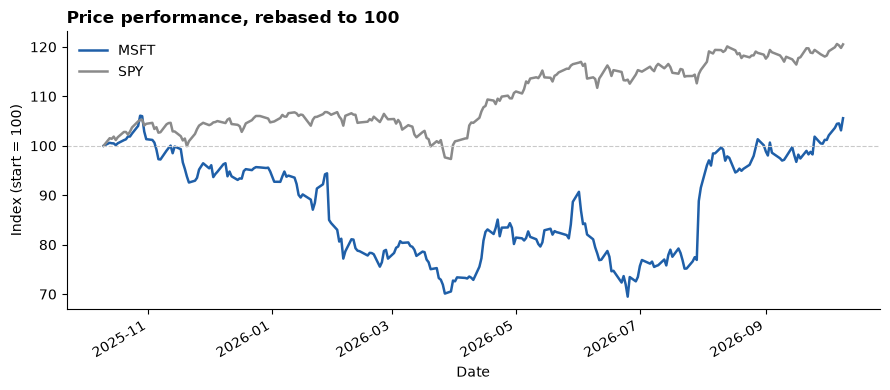

**Interpretation.** Both series start at 100, so the gap between the lines is the difference in total return. MSFT returned +5.6% from 2025-10-10 to 2026-10-09 versus +20.5% for SPY, underperforming by 14.9 percentage points.

In [10]:
viz.plot_performance(market.visualization_data["performance"])
plt.show()
md(f"**Interpretation.** Both series start at 100, so the gap between the lines is the difference in total return. {market.findings[0].statement}")

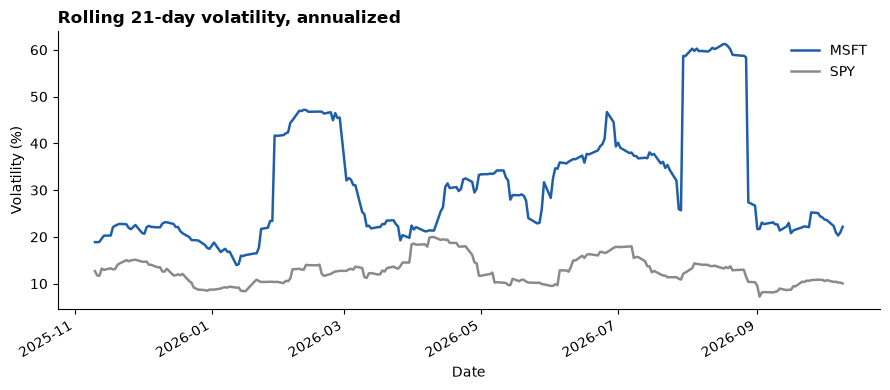

**Interpretation.** Each point is the annualized volatility of the previous 21 trading days; spikes mark periods of large daily moves. Annualized volatility was 32.8% versus 12.8% for SPY; beta was 0.98.

In [11]:
viz.plot_rolling_volatility(market.visualization_data["rolling_volatility"], settings.volatility_window)
plt.show()
md(f"**Interpretation.** Each point is the annualized volatility of the previous {settings.volatility_window} trading days; spikes mark periods of large daily moves. {market.findings[1].statement}")

## 5. Earnings Subagent

Retrieves annual income-statement, balance-sheet, and cash-flow items and computes growth, margins, cash conversion, and leverage. It also asks the optional SEC EDGAR tool for the latest periodic filing, so the figures can be traced to a primary document.

In [12]:
earnings = run_earnings_agent(task, tools)
show_result(earnings)

### `earnings_agent` — status: **success**

For the fiscal year ended 2026-06-30, MSFT reported revenue of USD 331.8 bn (+17.8% year over year) and net income of USD 133.7 bn, with free cash flow of USD 67.0 bn.

**Findings (with evidence ids)**
- Revenue for the fiscal year ended 2026-06-30 was USD 331.8 bn, +17.8% year over year (+16.1% CAGR since 2023). `[ERN-1, ERN-2, ERN-3]`
- Net income was USD 133.7 bn (+31.3% year over year); net margin was 40.3% versus 36.1% a year earlier. `[ERN-4, ERN-5, ERN-6]`
- Profitability: gross margin 67.9% (prior year 68.8%); operating margin 46.8% (prior year 45.6%). `[ERN-7, ERN-8]`
- Free cash flow was USD 67.0 bn (20.2% of revenue); operating cash flow was 1.37x net income. `[ERN-9, ERN-10]`
- Total debt was USD 56.8 bn against USD 20.9 bn of cash; debt-to-equity was 0.13x. `[ERN-11, ERN-12, ERN-13]`
- The most recent periodic filing is a 10-K filed on 2026-07-29 (period ended 2026-06-30). `[ERN-14]`

**Risks**
- _none_

**Limitations**
- Based on 4 annual periods through 2026-06-30; later quarterly results are not reflected.
- Line items are Yahoo Finance's standardized values and can differ from company-reported figures.

**Warnings**
- _none_

In [13]:
evidence_frame(earnings)

,id,claim,value,unit,kind,source,as_of,retrieved_at
0,ERN-1,"Revenue, fiscal year ended 2026-06-30",331839000000.0,USD,observed,Yahoo Finance (yfinance),2026-06-30,2026-10-11T12:13:05+00:00
1,ERN-2,Revenue growth versus the prior fiscal year,17.79,%,calculated,Yahoo Finance (yfinance),2026-06-30,2026-10-11T12:13:05+00:00
2,ERN-3,Revenue CAGR since 2023-06-30,16.12,%,calculated,Yahoo Finance (yfinance),2026-06-30,2026-10-11T12:13:05+00:00
3,ERN-4,"Net income, fiscal year ended 2026-06-30",133749000000.0,USD,observed,Yahoo Finance (yfinance),2026-06-30,2026-10-11T12:13:05+00:00
4,ERN-5,Net income growth versus the prior fiscal year,31.34,%,calculated,Yahoo Finance (yfinance),2026-06-30,2026-10-11T12:13:05+00:00
5,ERN-6,"Net margin, latest versus prior year","[40.31, 36.15]",%,calculated,Yahoo Finance (yfinance),2026-06-30,2026-10-11T12:13:05+00:00
6,ERN-7,"Gross margin, latest versus prior year","[67.94, 68.82]",%,calculated,Yahoo Finance (yfinance),2026-06-30,2026-10-11T12:13:05+00:00
7,ERN-8,"Operating margin, latest versus prior year","[46.78, 45.62]",%,calculated,Yahoo Finance (yfinance),2026-06-30,2026-10-11T12:13:05+00:00
8,ERN-9,"Free cash flow, fiscal year ended 2026-06-30",66987000000.0,USD,observed,Yahoo Finance (yfinance),2026-06-30,2026-10-11T12:13:05+00:00
9,ERN-10,Operating cash flow divided by net income,1.37,x,calculated,Yahoo Finance (yfinance),2026-06-30,2026-10-11T12:13:05+00:00


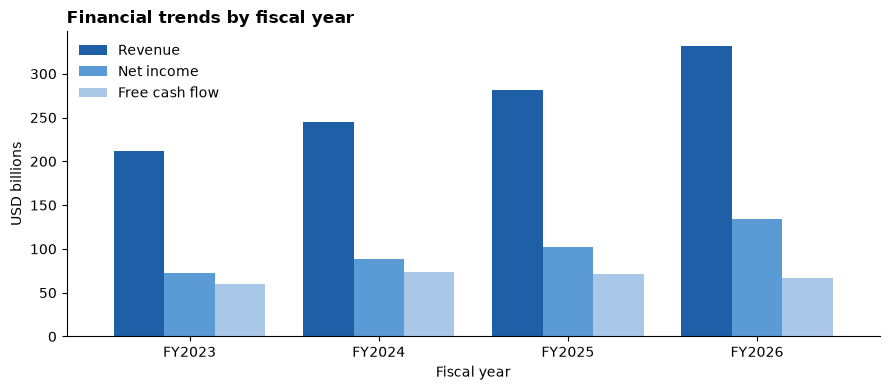

**Interpretation.** Bars show each fiscal year in billions. Revenue for the fiscal year ended 2026-06-30 was USD 331.8 bn, +17.8% year over year (+16.1% CAGR since 2023). Net income was USD 133.7 bn (+31.3% year over year); net margin was 40.3% versus 36.1% a year earlier.

In [14]:
viz.plot_financial_trends(earnings.visualization_data["financial_trends"], earnings.visualization_data["currency"])
plt.show()
md(f"**Interpretation.** Bars show each fiscal year in billions. {earnings.findings[0].statement} {earnings.findings[1].statement}")

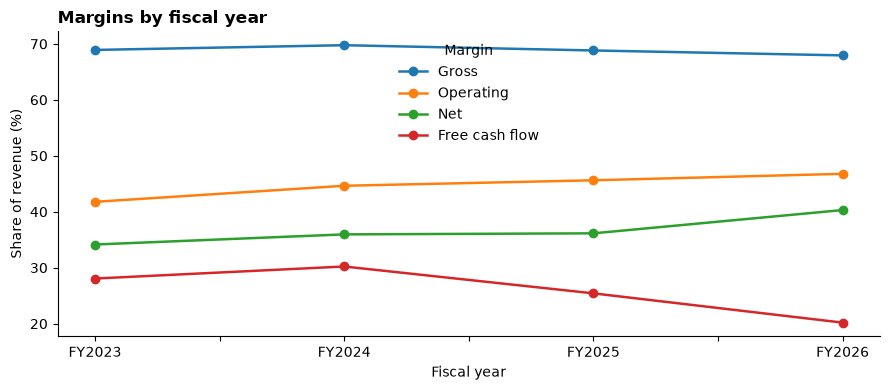

**Interpretation.** Each line is a profit measure as a share of revenue; a falling line means that measure grew more slowly than revenue. Profitability: gross margin 67.9% (prior year 68.8%); operating margin 46.8% (prior year 45.6%). Free cash flow was USD 67.0 bn (20.2% of revenue); operating cash flow was 1.37x net income.

In [15]:
viz.plot_margins(earnings.visualization_data["margins"])
plt.show()
md("**Interpretation.** Each line is a profit measure as a share of revenue; a falling line means that measure grew more slowly than revenue. "
   + " ".join(f.statement for f in earnings.findings[2:4]))

## 6. News prompt chain: Ingest → Preprocess → Classify → Extract → Summarize

The News Subagent is a LangGraph chain of five nodes. Each node's output is added to the chain's state and is the next node's input. Stages 1–2 are deterministic; stages 3–5 call the language model, and every model output is validated before the next stage may use it.

In [16]:
news_graph = build_news_graph(tools, llm)
print(news_graph.get_graph().draw_ascii())

+-----------+  
| __start__ |  
+-----------+  
       *       
       *       
       *       
  +--------+   
  | ingest |   
  +--------+   
       *       
       *       
       *       
+------------+ 
| preprocess | 
+------------+ 
       *       
       *       
       *       
 +----------+  
 | classify |  
 +----------+  
       *       
       *       
       *       
  +---------+  
  | extract |  
  +---------+  
       *       
       *       
       *       
+-----------+  
| summarize |  
+-----------+  
       *       
       *       
       *       
  +---------+  
  | __end__ |  
  +---------+  


Streaming the graph yields each stage's output as soon as that stage finishes. The cell below runs the chain once and keeps every stage's output for the cells that follow.

In [17]:
company = profile["name"]
stages, started = {}, time.perf_counter()
for update in news_graph.stream({"symbol": SYMBOL, "company": company}, stream_mode="updates"):
    for stage, output in update.items():
        stages[stage] = output
        print(f"{stage:<10} finished after {time.perf_counter() - started:5.1f}s -> {', '.join(output)}")

ingest     finished after   0.0s -> raw, feed_errors
preprocess finished after   0.0s -> clean, funnel


classify   finished after  41.3s -> classified


extract    finished after  76.9s -> events, funnel


summarize  finished after  88.2s -> summary


### Stage 1 — Ingest
Recent headlines from two feeds, retrieved through the registered news tool.

In [18]:
raw_articles = stages["ingest"]["raw"]
print(f"{len(raw_articles)} articles ingested:", pd.Series([a.source_feed for a in raw_articles]).value_counts().to_dict(),
      "| feed errors:", stages["ingest"]["feed_errors"] or "none")
records_frame(raw_articles, ["id", "published_at", "publisher", "source_feed", "title"]).head(8)

125 articles ingested: {'google_news': 100, 'yahoo_finance': 25} | feed errors: none


,id,published_at,publisher,source_feed,title
0,A001,2026-10-11 08:00:00+00:00,Barrons.com,yahoo_finance,"Four Years In, $40 Trillion Up: Why This AI-Fueled Bull Market Has Room to Run"
1,A002,2026-10-11 06:56:17+00:00,TIKR,yahoo_finance,"Why Infosys Can Shrug Off the US Green-Card Suspension, For Now"
2,A003,2026-10-11 05:26:26+00:00,TIKR,yahoo_finance,Amazon Reshuffles Alexa Leadership Right After Introducing New Tablet Lineup
3,A004,2026-10-10 20:44:06+00:00,Investing.com,yahoo_finance,Infosys sees no material impact from U.S. PERM suspension
4,A005,2026-10-10 20:15:00+00:00,Moneywise,yahoo_finance,"Trump awards science medals to Musk, Nadella and 4 other tech titans — 5 immigrants — hours after Vance targets them"
5,A006,2026-10-10 17:11:42+00:00,Insider Monkey,yahoo_finance,"Microsoft (MSFT) Posted 43% Azure Growth, Yet Trades Below Its Own Five-Year P/E. A Real Discount?"
6,A007,2026-10-10 17:03:01+00:00,Motley Fool,yahoo_finance,Advanced Micro Devices vs. Qualcomm: Which Technology Stock Is a Better Buy in 2026?
7,A008,2026-10-10 16:11:03+00:00,Simply Wall St.,yahoo_finance,"Is AI-Powered CashPro, AskGPS and New Debt Issuance Altering The Investment Case For Bank of America (BAC)?"


### Stage 2 — Preprocess
Clean the text, drop templated items and items outside the lookback window, merge exact duplicates, drop articles that do not name the company, cluster near-duplicate headlines (TF-IDF cosine similarity), and cap what is sent to the model. The count after every step is recorded.

In [19]:
clean_articles, funnel = stages["preprocess"]["clean"], stages["preprocess"]["funnel"]
funnel_frame(funnel)

,articles,removed_in_step,share_of_ingested
step,,,
ingested,125,0,100%
valid_and_recent,125,0,100%
after_exact_dedup,123,2,98%
relevant,69,54,55%
after_near_dedup,66,3,53%
selected_for_llm,12,54,10%


In [20]:
dropped = [a.title for a in raw_articles if not is_relevant(a, SYMBOL, company)]
print(f"Examples of the {len(dropped)} ingested headlines that do not name {company}:")
for title in dropped[:4]:
    print("  -", title[:110])
print(f"\nThe {len(clean_articles)} stories selected for the model. duplicate_count is how many ingested articles covered the story:")
records_frame(clean_articles, ["id", "published_at", "publisher", "duplicate_count", "also_reported_by", "title"])

Examples of the 23 ingested headlines that do not name Microsoft Corporation:
  - Four Years In, $40 Trillion Up: Why This AI-Fueled Bull Market Has Room to Run
  - Why Infosys Can Shrug Off the US Green-Card Suspension, For Now
  - Amazon Reshuffles Alexa Leadership Right After Introducing New Tablet Lineup
  - Infosys sees no material impact from U.S. PERM suspension

The 12 stories selected for the model. duplicate_count is how many ingested articles covered the story:


,id,published_at,publisher,duplicate_count,also_reported_by,title
0,A097,2026-10-09 00:07:00+00:00,AP News,2,[NBC News],"The Trump administration is suspending Microsoft from a green card program, alleging fraud"
1,A084,2026-10-08 18:13:38+00:00,Axios,2,[CNBC],"Trump's foreign worker crackdown comes for Microsoft, Adobe, IT firms"
2,A087,2026-10-08 09:46:26+00:00,Yahoo Finance,2,[CNBC],Microsoft debuts Nvidia-powered Surface Laptop Ultra as it aims for AI market
3,A111,2026-10-06 21:00:00+00:00,Microsoft Azure,2,[],Microsoft named a Leader in the 2026 Gartner® Magic Quadrant™ for Global Industrial AIoT Platforms
4,A073,2026-10-10 20:59:28+00:00,CNBC,1,[],Microsoft's Nadella says AI needs an ‘emergency brake’ that humans control
5,A006,2026-10-10 17:11:42+00:00,Insider Monkey,1,[],"Microsoft (MSFT) Posted 43% Azure Growth, Yet Trades Below Its Own Five-Year P/E. A Real Discount?"
6,A009,2026-10-10 15:20:27+00:00,Insider Monkey,1,[],Microsoft vs. Alphabet: Which AI Cloud Stock Is Cheaper After the Capital Spending?
7,A071,2026-10-10 14:22:23+00:00,CNBC,1,[],Vance says Microsoft replaced laid-off workers with foreign hires. Here’s what the visa data shows
8,A010,2026-10-10 14:15:00+00:00,Motley Fool,1,[],"Microsoft Stock Has Grown Roughly 15-Fold Since Satya Nadella Became CEO in 2014, a 27% Annual Growth Rate That Ende..."
9,A013,2026-10-10 10:12:09+00:00,Simply Wall St.,1,[],Microsoft Plus 2 Elite Defensive Stocks


### Stage 3 — Classify
The model labels each article with event type, relevance, expected impact, and time horizon. A label outside the allowed set is replaced by `unknown` rather than accepted.

In [21]:
classified = stages["classify"]["classified"]
records_frame(classified, ["id", "event_type", "relevance", "impact", "time_horizon", "title"])

,id,event_type,relevance,impact,time_horizon,title
0,A097,regulatory_legal,high,negative,medium_term,"The Trump administration is suspending Microsoft from a green card program, alleging fraud"
1,A084,regulatory_legal,high,negative,medium_term,"Trump's foreign worker crackdown comes for Microsoft, Adobe, IT firms"
2,A087,product,high,positive,medium_term,Microsoft debuts Nvidia-powered Surface Laptop Ultra as it aims for AI market
3,A111,product,high,positive,medium_term,Microsoft named a Leader in the 2026 Gartner® Magic Quadrant™ for Global Industrial AIoT Platforms
4,A073,management,high,neutral,medium_term,Microsoft's Nadella says AI needs an ‘emergency brake’ that humans control
5,A006,market_commentary,low,neutral,short_term,"Microsoft (MSFT) Posted 43% Azure Growth, Yet Trades Below Its Own Five-Year P/E. A Real Discount?"
6,A009,market_commentary,low,neutral,short_term,Microsoft vs. Alphabet: Which AI Cloud Stock Is Cheaper After the Capital Spending?
7,A071,management,medium,neutral,medium_term,Vance says Microsoft replaced laid-off workers with foreign hires. Here’s what the visa data shows
8,A010,market_commentary,low,neutral,medium_term,"Microsoft Stock Has Grown Roughly 15-Fold Since Satya Nadella Became CEO in 2014, a 27% Annual Growth Rate That Ende..."
9,A013,market_commentary,low,neutral,short_term,Microsoft Plus 2 Elite Defensive Stocks


### Stage 4 — Extract
For every article that is not low-relevance, the model extracts the event, entities, figures, dates, risks, and catalysts. Entities, figures, and dates are kept only if they literally occur in the headline, which removes invented values. Source, URL, and date are copied from the article, never generated.

In [22]:
events = stages["extract"]["events"]
print(f"{len(events)} material events extracted from {len(classified)} classified articles")
records_frame(events, ["id", "article_id", "event", "entities", "figures", "risks", "catalysts", "source", "event_date", "extraction_method"])

7 material events extracted from 12 classified articles


,id,article_id,event,entities,figures,risks,catalysts,source,event_date,extraction_method
0,E1,A097,"The Trump administration suspended Microsoft from a green card program, alleging fraud.",[Trump administration],[],[Legal and regulatory risks due to allegations of fraud],[],AP News,2026-10-09,llm
1,E2,A084,"Trump's foreign worker crackdown comes for Microsoft, Adobe, IT firms","[Adobe, IT firms]",[],[Potential impact of foreign worker crackdown on operations],[],Axios,2026-10-08,llm
2,E3,A087,Microsoft debuts Nvidia-powered Surface Laptop Ultra as it aims for AI market.,[Nvidia],[],[],[],Yahoo Finance,2026-10-08,llm
3,E4,A111,Microsoft named a Leader in the 2026 Gartner® Magic Quadrant™ for Global Industrial AIoT Platforms,[Gartner® Magic Quadrant™],[],[],[Recognition in a key industry benchmark],Microsoft Azure,2026-10-06,llm
4,E5,A073,Microsoft's Nadella says AI needs an ‘emergency brake’ that humans control.,[Nadella],[],[],[],CNBC,2026-10-10,llm
5,E6,A067,"Trump administration freezes green cards for Microsoft, IT firms, probes universities","[Trump administration, Microsoft, IT firms, universities]",[],[Regulatory scrutiny and potential legal challenges],[],Reuters,2026-10-10,llm
6,E7,A071,Vance says Microsoft replaced laid-off workers with foreign hires. Here’s what the visa data shows,[Vance],[],[],[],CNBC,2026-10-10,llm


### Stage 5 — Summarize
The model writes the news paragraph from the extracted events only and cites them as `[E1]`, `[E2]`, … Citations are checked against the event list; if none are valid, a deterministic summary is used instead.

In [23]:
news_summary = stages["summarize"]["summary"]
md(news_summary["summary"])
print("method:", news_summary["method"], "| cited events:", news_summary["cited_event_ids"])

Microsoft faces regulatory challenges as the Trump administration suspends its participation in a green card program, alleging fraud [E1], and freezes green cards for IT firms, including Microsoft [E6]. Meanwhile, the company debuts a Nvidia-powered Surface Laptop Ultra, positioning itself for the AI market [E3], and is named a Leader in the 2026 Gartner® Magic Quadrant™ for Global Industrial AIoT Platforms [E4]. Additionally, Microsoft's CEO Nadella acknowledges the need for an 'emergency brake' in AI development [E5]. The overall balance of developments is mixed, with positive advancements in product innovation and neutral regulatory outlooks, though there are ongoing concerns about regulatory scrutiny.

method: llm | cited events: ['E1', 'E6', 'E3', 'E4', 'E5']


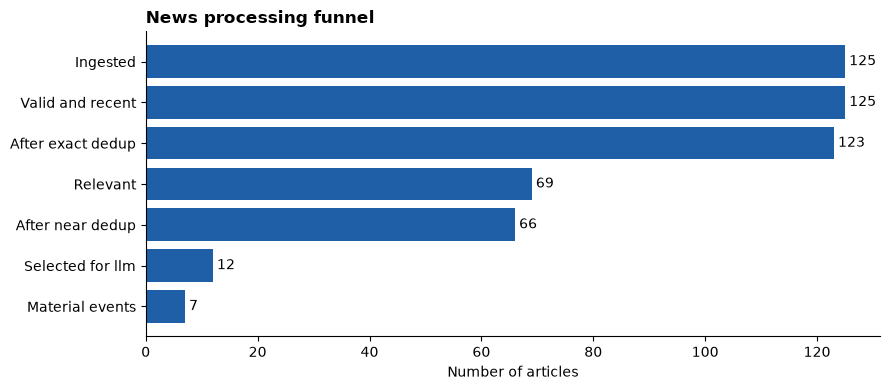

**Interpretation.** Of 125 ingested articles, 66 distinct, company-relevant stories remained after deduplication and filtering; the 12 most widely covered and most recent went to the model, which judged 7 of them material.

In [24]:
full_funnel = stages["extract"]["funnel"]
viz.plot_news_funnel(full_funnel)
plt.show()
md(f"**Interpretation.** Of {full_funnel['ingested']} ingested articles, {full_funnel['after_near_dedup']} distinct, company-relevant stories remained after "
   f"deduplication and filtering; the {full_funnel['selected_for_llm']} most widely covered and most recent went to the model, which judged "
   f"{full_funnel['material_events']} of them material.")

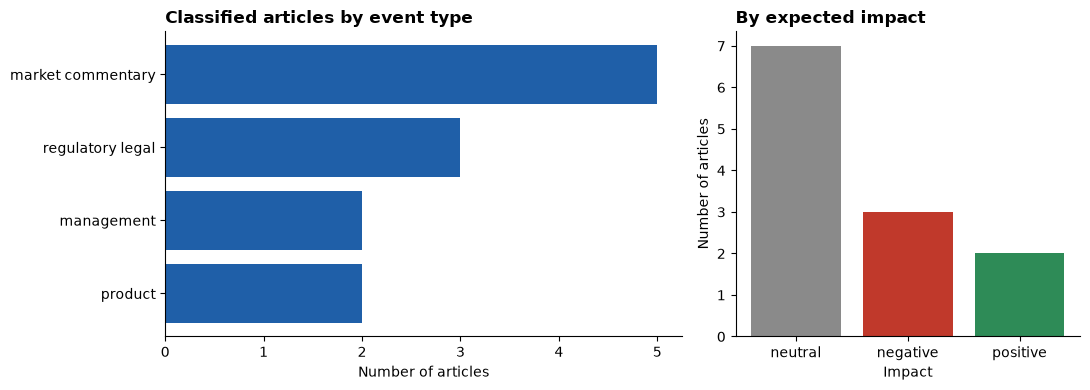

**Interpretation.** Event types of the 12 classified articles (left) and their expected impact (right). These labels are the model's judgment of headlines, not observed facts.

In [25]:
categories = pd.Series([a.event_type for a in classified]).value_counts().to_dict()
impacts = pd.Series([a.impact for a in classified]).value_counts().to_dict()
viz.plot_news_categories(categories, impacts)
plt.show()
md(f"**Interpretation.** Event types of the {len(classified)} classified articles (left) and their expected impact (right). "
   "These labels are the model's judgment of headlines, not observed facts.")

## 7. News Subagent: the chain as a standard subagent result

`run_news_agent` runs the same graph and packages its state in the schema every subagent shares: summary, findings, evidence, risks, catalysts, limitations, warnings, and chart-ready data. The chain runs again here, so its labels and wording can differ slightly from section 6.

In [26]:
news = run_news_agent(task, tools, llm)
show_result(news)

### `news_agent` — status: **success**

Microsoft faces regulatory challenges as the Trump administration suspends its participation in a green card program, alleging fraud [E1], and freezes green cards for IT firms, including Microsoft [E6]. Meanwhile, the company debuts a Nvidia-powered Surface Laptop Ultra, positioning itself for the AI market [E3], and is named a Leader in the 2026 Gartner® Magic Quadrant™ for Global Industrial AIoT Platforms [E4]. Additionally, Microsoft's CEO Nadella acknowledges the need for an 'emergency brake' in AI development [E5]. The overall balance of developments is mixed, with positive advancements in product innovation and neutral regulatory outlooks, though there are ongoing concerns about regulatory scrutiny.

**Findings (with evidence ids)**
- The Trump administration suspended Microsoft from a green card program, alleging fraud (AP News, 2026-10-09; classified regulatory_legal, negative impact, high relevance) `[NEWS-1]`
- Trump's foreign worker crackdown comes for Microsoft, Adobe, IT firms (Axios, 2026-10-08; classified regulatory_legal, negative impact, high relevance) `[NEWS-2]`
- Microsoft debuts Nvidia-powered Surface Laptop Ultra as it aims for AI market (Yahoo Finance, 2026-10-08; classified product, positive impact, high relevance) `[NEWS-3]`
- Microsoft named a Leader in the 2026 Gartner® Magic Quadrant™ for Global Industrial AIoT Platforms (Microsoft Azure, 2026-10-06; classified product, positive impact, high relevance) `[NEWS-4]`
- Microsoft's Nadella says AI needs an ‘emergency brake’ that humans control (CNBC, 2026-10-10; classified management, neutral impact, high relevance) `[NEWS-5]`
- Trump administration freezes green cards for Microsoft, IT firms, probes universities (Reuters, 2026-10-10; classified regulatory_legal, negative impact, high relevance) `[NEWS-6]`

**Risks**
- Legal and regulatory risks due to allegations of fraud [E1]
- Potential impact of foreign worker crackdown on operations [E2]
- Regulatory scrutiny and potential legal challenges [E6]

**Catalysts**
- Recognition in a key industry benchmark [E4]

**Limitations**
- News analysis is based on headlines only; full article text is not retrieved.
- Event type, relevance, impact, risks, and catalysts are judgments of a small local language model, not observed facts.
- Only the 12 most widely covered and most recent stories of the last 30 days were analyzed.

**Warnings**
- _none_

In [27]:
evidence_frame(news)[["id", "claim", "value", "source", "as_of"]]

,id,claim,value,source,as_of
0,NEWS-1,"The Trump administration suspended Microsoft from a green card program, alleging fraud.","{'event_type': 'regulatory_legal', 'impact': 'negative', 'relevance': 'high'}",AP News,2026-10-09
1,NEWS-2,"Trump's foreign worker crackdown comes for Microsoft, Adobe, IT firms","{'event_type': 'regulatory_legal', 'impact': 'negative', 'relevance': 'high'}",Axios,2026-10-08
2,NEWS-3,Microsoft debuts Nvidia-powered Surface Laptop Ultra as it aims for AI market.,"{'event_type': 'product', 'impact': 'positive', 'relevance': 'high'}",Yahoo Finance,2026-10-08
3,NEWS-4,Microsoft named a Leader in the 2026 Gartner® Magic Quadrant™ for Global Industrial AIoT Platforms,"{'event_type': 'product', 'impact': 'positive', 'relevance': 'high'}",Microsoft Azure,2026-10-06
4,NEWS-5,Microsoft's Nadella says AI needs an ‘emergency brake’ that humans control.,"{'event_type': 'management', 'impact': 'neutral', 'relevance': 'high'}",CNBC,2026-10-10
5,NEWS-6,"Trump administration freezes green cards for Microsoft, IT firms, probes universities","{'event_type': 'regulatory_legal', 'impact': 'negative', 'relevance': 'high'}",Reuters,2026-10-10
6,NEWS-7,Vance says Microsoft replaced laid-off workers with foreign hires. Here’s what the visa data shows,"{'event_type': 'management', 'impact': 'neutral', 'relevance': 'medium'}",CNBC,2026-10-10


## 8. The main agent and its subagents

The whole graph is the agent. `resolve` works out which company is meant. `main_agent` is one turn of the model with the subagents bound to it as tools. The `subagents` node is LangGraph's prebuilt `ToolNode`: it runs the subagents the model called and returns their reports to it. When the model stops calling subagents and answers, `brief` assembles the output.

In [28]:
agent = InvestmentResearchAgent(llm)
print(agent.graph.get_graph().draw_ascii())

                    +-----------+               
                    | __start__ |               
                    +-----------+               
                          *                     
                          *                     
                          *                     
                     +---------+                
                     | resolve |                
                     +---------+...             
                    ...            ....         
                   .                   ...      
                 ..                       ...   
        +------------+                       .. 
        | main_agent |                        . 
        +------------+                        . 
           *        ...                       . 
         **            .                      . 
        *               ..                    . 
+-----------+         +-------+               . 
| subagents |         | brief |             ..  
+-----------+       

**What the model is given.** Each subagent is offered as a tool: a name, a description, and its arguments. The description is all the model knows about a subagent, and it is the only thing that drives selection. Attaching a new subagent means adding one `@tool` function in `src/subagents.py`.

In [29]:
pd.DataFrame([
    {"tool (subagent)": subagent.name, "description shown to the model": subagent.description,
     "arguments": ", ".join(subagent.tool_call_schema.model_json_schema()["properties"])}
    for subagent in build_subagent_tools(tools, llm)
]).set_index("tool (subagent)")

,description shown to the model,arguments
tool (subagent),,
market_agent,"Share-price analysis: returns, volatility, drawdowns, trend, and comparison with a benchmark. Can add macroeconomic ...",include_macro
earnings_agent,"Financial-statement analysis: revenue, profit, margins, cash flow, debt, and the latest SEC filing.",
news_agent,"Recent-news analysis: announcements, product launches, regulatory and legal events, and analyst actions, with the ri...",


**Choosing subagents by tool calling.** Nothing in the code maps a question to a subagent. To show that the model's choice depends on the question, the same agent is given seven sample questions of different scope about the same company. A narrow question should lead to one subagent; only a broad request should lead to all three. The table shows which subagents the model called for each question. (This is the assignment's Routing pattern.)

In [30]:
SAMPLE_QUESTIONS = {
    "Price performance": "Analyze the stock's one-year price performance and volatility.",
    "Financial trends": "Analyze revenue, net income, and margin trends.",
    "Recent announcements": "Summarize recent product and regulatory announcements.",
    "Earnings and price reaction": "Analyze the latest earnings results and the share-price movement.",
    "News risk and volatility": "What are the main risks from recent news and how volatile is the stock?",
    "Interest-rate sensitivity": "How might interest rates affect this stock's valuation?",
    "Comprehensive research": QUESTION,
}
sample_runs = {}
for label, question in SAMPLE_QUESTIONS.items():
    started = time.perf_counter()
    sample_runs[label] = agent.run(question, SYMBOL)
    called = [d.subagent for d in sample_runs[label]["subagent_calls"] if d.called]
    print(f"{time.perf_counter() - started:5.1f}s  {label}: {called}")

pd.DataFrame([
    {"question": label, "subagent": d.subagent, "called": "yes" if d.called else "no", "status": d.status}
    for label, run in sample_runs.items() for d in run["subagent_calls"]
]).set_index(["question", "subagent"])

 12.1s  Price performance: ['market_agent']


 19.5s  Financial trends: ['earnings_agent']


104.8s  Recent announcements: ['news_agent']


 21.9s  Earnings and price reaction: ['market_agent', 'earnings_agent']


105.3s  News risk and volatility: ['market_agent', 'news_agent']


 15.9s  Interest-rate sensitivity: ['market_agent']


146.1s  Comprehensive research: ['market_agent', 'earnings_agent', 'news_agent']


called   status
question                    subagent                      
Price performance           market_agent      yes  success
                            earnings_agent     no  skipped
                            news_agent         no  skipped
Financial trends            market_agent       no  skipped
                            earnings_agent    yes  success
                            news_agent         no  skipped
Recent announcements        market_agent       no  skipped
                            earnings_agent     no  skipped
                            news_agent        yes  success
Earnings and price reaction market_agent      yes  success
                            earnings_agent    yes  success
                            news_agent         no  skipped
News risk and volatility    market_agent      yes  success
                            earnings_agent     no  skipped
                            news_agent        yes  success
Interest-rate sensitivity   market_agent      yes  success
                            earnings_agent     no  skipped
                            news_agent         no  skipped
Comprehensive research      market_agent      yes  success
                            earnings_agent    yes  success
                            news_agent        yes  success

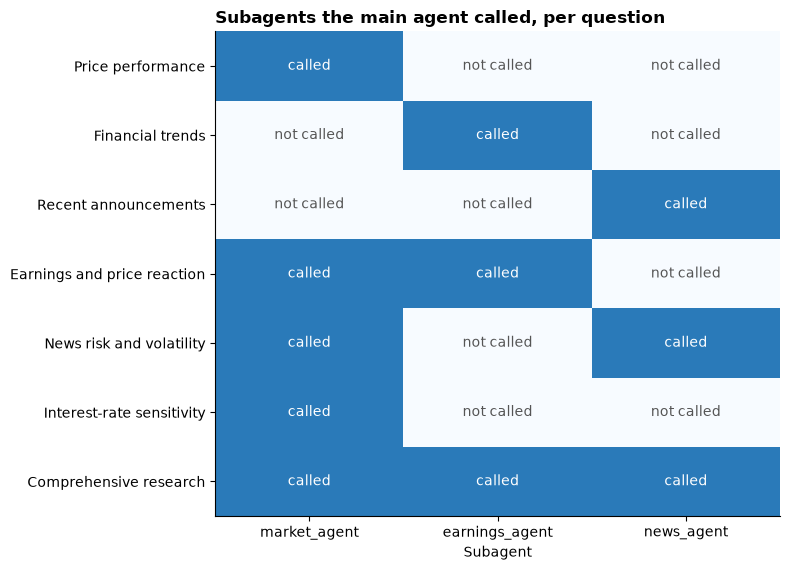

**Interpretation.** Each row is one question, and the calls differ with the question; subagents called per question — Price performance: 1; Financial trends: 1; Recent announcements: 1; Earnings and price reaction: 2; News risk and volatility: 2; Interest-rate sensitivity: 1; Comprehensive research: 3.

In [31]:
viz.plot_subagent_calls({label: run["subagent_calls"] for label, run in sample_runs.items()})
plt.show()
chosen = "; ".join(f"{label}: {sum(d.called for d in run['subagent_calls'])}" for label, run in sample_runs.items())
md(f"**Interpretation.** Each row is one question, and the calls differ with the question; subagents called per question — {chosen}.")

**The loop, message by message.** For one two-subagent question: the request, the model's tool calls, each subagent's report coming back as a tool message, and the model's answer.

In [32]:
def message_trace(run):
    rows = []
    for message in run["messages"]:
        calls = getattr(message, "tool_calls", None)
        text = "; ".join(f"call {c['name']}({c['args']})" for c in calls) if calls else str(message.content)
        rows.append({"from": {"human": "user", "ai": "main_agent", "tool": message.name}.get(message.type, message.type), "content": text[:330]})
    return pd.DataFrame(rows)

message_trace(sample_runs["News risk and volatility"])

,from,content
0,user,Company: Microsoft Corporation (MSFT)\nResearch question: What are the main risks from recent news and how volatile ...
1,main_agent,call news_agent({}); call market_agent({'include_macro': False})
2,news_agent,Microsoft faces regulatory challenges as the Trump administration suspends its participation in a green card program...
3,market_agent,"MSFT returned +5.6% from 2025-10-10 to 2026-10-09 against +20.5% for SPY, with 32.8% annualized volatility and a -34..."
4,main_agent,Microsoft's stock has shown volatility with a 32.8% annualized volatility and a -34.5% maximum drawdown. Recent news...


For the interest-rate question the model also sets the Market Subagent's `include_macro` option, which makes that subagent fetch a FRED series:

In [33]:
rate_run = sample_runs["Interest-rate sensitivity"]
print("tool calls by the main agent:", [(c["name"], c["args"]) for m in rate_run["messages"] if m.type == "ai" for c in m.tool_calls])
print("data tools used:", [c.tool_name for c in rate_run["tool_call_log"]])
md(rate_run["answer"])

tool calls by the main agent: [('market_agent', {'include_macro': True})]
data tools used: ['get_company_profile', 'get_price_history', 'get_benchmark_history', 'get_macro_series']


Interest rates may affect Microsoft Corporation (MSFT) valuation by influencing the discount rate applied to long-duration growth earnings, as higher long-term yields increase the discount rate for such earnings. The stock has a volatility of 32.8% compared to the benchmark, which is 2.6x the benchmark's volatility, indicating larger price swings. Additionally, the stock experienced a -34.5% drawdown, highlighting material downside risk. These factors suggest that changes in interest rates could impact the stock's valuation, particularly in the context of long-term growth earnings and the associated discount rate.

## 9. The agent end to end: a question in, a research brief out

One call runs the whole graph:

```python
agent = InvestmentResearchAgent()
state = agent.run("Produce a comprehensive investment research report.", symbol="MSFT")
state = agent.run("How risky is Tesla right now?")   # the ticker is found from the question
```

The comprehensive question for the default symbol was already run in section 8, so the cell below reuses that run and shows what the state contains: the tool-call log and the brief.

In [34]:
state = sample_runs["Comprehensive research"]
print(f"subagents called: {[d.subagent for d in state['subagent_calls'] if d.called]} | evidence items: {len(state['evidence'])} | "
      f"data-tool calls: {len(state['tool_call_log'])} | warnings: {len(state['warnings'])}")

subagents called: ['market_agent', 'earnings_agent', 'news_agent'] | evidence items: 32 | data-tool calls: 7 | warnings: 0


Tool-call log of that run. Calls that take about 0 s were served from the disk cache.

In [35]:
pd.DataFrame([c.model_dump() for c in state["tool_call_log"]])[["tool_name", "arguments", "status", "duration_seconds", "output_summary", "error"]]

,tool_name,arguments,status,duration_seconds,output_summary,error
0,get_company_profile,{'symbol': 'MSFT'},success,0.001,"fields: symbol, name, quote_type, sector, industry, country, currency, financial_currency",None
1,get_financial_statements,{'symbol': 'MSFT'},success,0.021,"4 rows x 9 columns, 2023-06-30 to 2026-06-30",None
2,get_price_history,"{'symbol': 'MSFT', 'period': '1y'}",success,0.035,"251 rows x 5 columns, 2025-10-10 to 2026-10-09",None
3,get_company_news,"{'symbol': 'MSFT', 'company_name': 'Microsoft Corporation', 'lookback_days': 30}",success,0.019,"125 articles from feeds {'yahoo_finance': 25, 'google_news': 100}",None
4,get_sec_filings,{'symbol': 'MSFT'},success,0.018,4 rows x 4 columns,None
5,get_benchmark_history,"{'benchmark': 'SPY', 'period': '1y'}",success,0.025,"251 rows x 5 columns, 2025-10-10 to 2026-10-09",None
6,get_macro_series,{'series_id': 'DGS10'},success,0.002,"248 rows x 1 columns, 2025-10-14 to 2026-10-08",None


**The agent's output.** The *Answer* paragraph is written by the main agent's model from the subagent reports. Everything below it is copied from the subagents' results, so each figure there is exactly what the calculation produced, and every finding ends with the ids of the evidence that supports it.

In [36]:
md(brief_of(state))

# Research brief: Microsoft Corporation (MSFT)
**Question:** Produce a comprehensive investment research report.
**Company:** Technology / Software - Infrastructure, United States

## Answer
Microsoft Corporation (MSFT) has shown mixed performance in the market, with a 5.6% return from 2025-10-10 to 2026-10-09, underperforming the SPY index by 14.9 percentage points. The stock exhibits 32.8% annualized volatility and a -34.5% maximum drawdown, indicating significant downside risk. The company's financials show strong revenue growth, with USD 331.8 billion in revenue for the fiscal year ended 2026-06-30, a 17.8% increase year-over-year, and net income of USD 133.7 billion, a 31.3% increase. The company's free cash flow was USD 67.0 billion, and its debt-to-equity ratio was 0.13x. 

In terms of news, Microsoft faces regulatory challenges, including a suspension from a green card program and a freeze on green cards for IT firms, including Microsoft. However, the company is also launching a Nvidia-powered Surface Laptop Ultra to position itself in the AI market and has been named a Leader in the 2026 Gartner® Magic Quadrant™ for Global Industrial AIoT Platforms. Additionally, Microsoft's CEO, Nadella, acknowledges the need for an 'emergency brake' in AI development. 

Overall, the company's performance is influenced by both positive developments in product innovation and neutral regulatory outlooks, though there

_Written by the main agent from the subagent reports. The sections below are copied from the subagents' results._

## Subagents
- `market_agent`: called
- `earnings_agent`: called
- `news_agent`: called

## Market performance (success)
MSFT returned +5.6% from 2025-10-10 to 2026-10-09 against +20.5% for SPY, with 32.8% annualized volatility and a -34.5% maximum drawdown.

- MSFT returned +5.6% from 2025-10-10 to 2026-10-09 versus +20.5% for SPY, underperforming by 14.9 percentage points. `[MKT-1, MKT-3, MKT-4]`
- Annualized volatility was 32.8% versus 12.8% for SPY; beta was 0.98. `[MKT-2, MKT-5, MKT-6]`
- Maximum drawdown was -34.5%, from the peak on 2025-10-28 to the trough on 2026-06-25. `[MKT-7]`
- Trailing returns: 1M +8.7%, 3M +37.1%, 6M +44.9%. `[MKT-8]`
- The last close (535.07) is 7.0% above the 50-day moving average (500.19). `[MKT-9]`
- The last close (535.07) is 23.7% above the 200-day moving average (432.70). `[MKT-10]`
- Macro (observed): 10-year US Treasury yield was 5.22% on 2026-10-08, a change of +1.19 percentage points since 2025-10-14. `[MKT-11]`
- Macro (interpretation, not an observed fact): Higher long-term yields raise discount rates applied to long-duration growth earnings. `[MKT-11]`

## Financial analysis (success)
For the fiscal year ended 2026-06-30, MSFT reported revenue of USD 331.8 bn (+17.8% year over year) and net income of USD 133.7 bn, with free cash flow of USD 67.0 bn.

- Revenue for the fiscal year ended 2026-06-30 was USD 331.8 bn, +17.8% year over year (+16.1% CAGR since 2023). `[ERN-1, ERN-2, ERN-3]`
- Net income was USD 133.7 bn (+31.3% year over year); net margin was 40.3% versus 36.1% a year earlier. `[ERN-4, ERN-5, ERN-6]`
- Profitability: gross margin 67.9% (prior year 68.8%); operating margin 46.8% (prior year 45.6%). `[ERN-7, ERN-8]`
- Free cash flow was USD 67.0 bn (20.2% of revenue); operating cash flow was 1.37x net income. `[ERN-9, ERN-10]`
- Total debt was USD 56.8 bn against USD 20.9 bn of cash; debt-to-equity was 0.13x. `[ERN-11, ERN-12, ERN-13]`
- The most recent periodic filing is a 10-K filed on 2026-07-29 (period ended 2026-06-30). `[ERN-14]`

## News and events (success)
Microsoft faces regulatory challenges as the Trump administration suspends its participation in a green card program, alleging fraud [E1], and freezes green cards for IT firms, including Microsoft [E6]. Meanwhile, the company debuts a Nvidia-powered Surface Laptop Ultra, positioning itself for the AI market [E3], and is named a Leader in the 2026 Gartner® Magic Quadrant™ for Global Industrial AIoT Platforms [E4]. Additionally, Microsoft's CEO Nadella acknowledges the need for an 'emergency brake' in AI development [E5]. The overall balance of developments is mixed, with positive advancements in product innovation and neutral regulatory outlooks, though there are ongoing concerns about regulatory scrutiny.

- The Trump administration suspended Microsoft from a green card program, alleging fraud (AP News, 2026-10-09; classified regulatory_legal, negative impact, high relevance) `[NEWS-1]`
- Trump's foreign worker crackdown comes for Microsoft, Adobe, IT firms (Axios, 2026-10-08; classified regulatory_legal, negative impact, high relevance) `[NEWS-2]`
- Microsoft debuts Nvidia-powered Surface Laptop Ultra as it aims for AI market (Yahoo Finance, 2026-10-08; classified product, positive impact, high relevance) `[NEWS-3]`
- Microsoft named a Leader in the 2026 Gartner® Magic Quadrant™ for Global Industrial AIoT Platforms (Microsoft Azure, 2026-10-06; classified product, positive impact, high relevance) `[NEWS-4]`
- Microsoft's Nadella says AI needs an ‘emergency brake’ that humans control (CNBC, 2026-10-10; classified management, neutral impact, high relevance) `[NEWS-5]`
- Trump administration freezes green cards for Microsoft, IT firms, probes universities (Reuters, 2026-10-10; classified regulatory_legal, negative impact, high relevance) `[NEWS-6]`

## Risks
- Volatility is 2.6x the benchmark's, so price swings are larger.
- A -34.5% drawdown within the period shows material downside risk.
- Legal and regulatory risks due to allegations of fraud [E1]
- Potential impact of foreign worker crackdown on operations [E2]
- Regulatory scrutiny and potential legal challenges [E6]

## Catalysts
- Recognition in a key industry benchmark [E4]

## Limitations and warnings
- Based on adjusted daily closes from 2025-10-10 to 2026-10-09; past performance does not predict future returns.
- SPY is a broad-market benchmark and may not reflect the company's sector.
- Based on 4 annual periods through 2026-06-30; later quarterly results are not reflected.
- Line items are Yahoo Finance's standardized values and can differ from company-reported figures.
- News analysis is based on headlines only; full article text is not retrieved.
- Event type, relevance, impact, risks, and catalysts are judgments of a small local language model, not observed facts.
- Only the 12 most widely covered and most recent stories of the last 30 days were analyzed.

## Sources
- AP News (retrieved 2026-10-11T14:11:35+00:00)
- Axios (retrieved 2026-10-11T14:11:35+00:00)
- CNBC (retrieved 2026-10-11T14:11:35+00:00)
- FRED, Federal Reserve Bank of St. Louis (DGS10) (retrieved 2026-10-11T12:13:07+00:00)
- Microsoft Azure (retrieved 2026-10-11T14:11:35+00:00)
- Reuters (retrieved 2026-10-11T14:11:35+00:00)
- SEC EDGAR (retrieved 2026-10-11T12:13:08+00:00)
- Yahoo Finance (retrieved 2026-10-11T14:11:35+00:00)
- Yahoo Finance (yfinance) (retrieved 2026-10-11T12:13:05+00:00)

### A free-text question
No symbol is passed here. The model names the company in the question, a ticker search maps that name to a symbol, and the run continues as before.

In [37]:
started = time.perf_counter()
free_text = agent.run("What are the main risks from recent news on Tesla, and how volatile is the stock?")
print(f"{time.perf_counter() - started:.0f}s | resolved symbol: {free_text['symbol']} ({free_text['company_profile']['name']}) | "
      f"subagents called: {[d.subagent for d in free_text['subagent_calls'] if d.called]}")
print("first data-tool calls:", [c.tool_name for c in free_text["tool_call_log"]][:2])
md(free_text["answer"])

165s | resolved symbol: TSLA (Tesla, Inc.) | subagents called: ['market_agent', 'news_agent']
first data-tool calls: ['resolve_symbol', 'get_company_profile']


Tesla, Inc. (TSLA) faced mixed news in recent periods, with positive developments in earnings and market sentiment. The company beat delivery estimates by 25,000 vehicles and saw a surge in shares following a special event, while analysts praised its potential in the AI space. However, regulatory actions in Europe, such as the drop of 'Full Self-Driving,' led to a 10% decline in revenue, creating uncertainty. The stock returned -7.4% from 2025-10-10 to 2026-10-09, with 45.2% annualized volatility and a -39.1% maximum drawdown. The stock is highly volatile, with price swings larger than the benchmark's, and beta of 2.23, indicating above-market sensitivity to broad sell-offs. The risks include potential impact on consumer confidence and adoption of Full Self-Driving, global sales slump risk, and demand shortfall risk.

## 10. Five companies, and reliability

### Microsoft, Apple, Alphabet (Google), Meta, and Tesla
The same call, once per company, with the same comprehensive question. Every run generates its text afresh, so the timings are the real cost of a run on this machine.

In [38]:
COMPANIES = {"Microsoft": "MSFT", "Apple": "AAPL", "Alphabet (Google)": "GOOGL", "Meta": "META", "Tesla": "TSLA"}

runs = {}
for company_label, ticker in COMPANIES.items():
    started = time.perf_counter()
    runs[ticker] = agent.run(QUESTION, ticker)
    print(f"{ticker}: {time.perf_counter() - started:4.0f}s end to end | subagents called: {[d.subagent for d in runs[ticker]['subagent_calls'] if d.called]}")

def run_summary(run):
    news_result = result_of(run, "news_agent")
    funnel = news_result.visualization_data.get("funnel", {}) if news_result else {}
    status = lambda name: getattr(result_of(run, name), "status", "not called")
    return {
        "company": run["company_profile"]["name"], "sector": run["company_profile"]["sector"],
        "market": status("market_agent"), "earnings": status("earnings_agent"), "news": status("news_agent"),
        "evidence items": len(run["evidence"]), "data-tool calls": len(run["tool_call_log"]),
        "tool errors": sum(not c.ok for c in run["tool_call_log"]), "warnings": len(run["warnings"]),
        "news funnel": " → ".join(str(funnel.get(k, "-")) for k in ("ingested", "after_near_dedup", "selected_for_llm", "material_events")),
    }

pd.DataFrame({ticker: run_summary(run) for ticker, run in runs.items()}).T

MSFT:  151s end to end | subagents called: ['market_agent', 'earnings_agent', 'news_agent']


AAPL:  152s end to end | subagents called: ['market_agent', 'earnings_agent', 'news_agent']


GOOGL:  160s end to end | subagents called: ['market_agent', 'earnings_agent', 'news_agent']


META:  172s end to end | subagents called: ['market_agent', 'earnings_agent', 'news_agent']


TSLA:  192s end to end | subagents called: ['market_agent', 'earnings_agent', 'news_agent']


,company,sector,market,earnings,news,evidence items,data-tool calls,tool errors,warnings,news funnel
MSFT,Microsoft Corporation,Technology,success,success,success,32,7,0,0,125 → 66 → 12 → 7
AAPL,Apple Inc.,Technology,success,success,success,34,7,0,0,123 → 98 → 12 → 9
GOOGL,Alphabet Inc.,Communication Services,success,success,success,33,6,0,0,125 → 59 → 12 → 9
META,"Meta Platforms, Inc.",Communication Services,success,success,success,35,6,0,0,123 → 100 → 12 → 11
TSLA,"Tesla, Inc.",Consumer Cyclical,success,success,success,37,8,0,0,125 → 105 → 12 → 11


The headline numbers side by side. They come from the deterministic market and earnings calculations, so they do not depend on the language model.

In [39]:
def evidence_value(run, agent_name, claim_start):
    result = result_of(run, agent_name)
    return next((item.value for item in result.evidence if item.claim.startswith(claim_start)), None) if result else None

pd.DataFrame({
    ticker: {
        "1y return (%)": evidence_value(run, "market_agent", f"{ticker} total return"),
        "vs SPY (pct. points)": evidence_value(run, "market_agent", f"{ticker} excess return"),
        "volatility (%)": evidence_value(run, "market_agent", f"{ticker} annualized volatility"),
        "max drawdown (%)": evidence_value(run, "market_agent", f"{ticker} maximum drawdown"),
        "revenue growth (%)": evidence_value(run, "earnings_agent", "Revenue growth"),
        "net income growth (%)": evidence_value(run, "earnings_agent", "Net income growth"),
        "material news events": len(getattr(result_of(run, "news_agent"), "evidence", [])),
    }
    for ticker, run in runs.items()
}).T

,1y return (%),vs SPY (pct. points),volatility (%),max drawdown (%),revenue growth (%),net income growth (%),material news events
MSFT,5.58,-14.93,32.82,-34.50,17.79,31.34,7.0
AAPL,37.76,17.25,24.47,-13.80,6.43,19.50,9.0
GOOGL,49.04,28.52,31.63,-21.05,15.09,32.01,9.0
META,2.24,-18.27,41.75,-29.94,22.17,-3.05,11.0
TSLA,-7.45,-27.96,45.21,-39.10,-2.93,-46.79,11.0


The agent's brief for each of the other four companies (Microsoft's is in section 9).

In [40]:
md(brief_of(runs["AAPL"]))

# Research brief: Apple Inc. (AAPL)
**Question:** Produce a comprehensive investment research report.
**Company:** Technology / Consumer Electronics, United States

## Answer
Apple Inc. (AAPL) has shown strong performance in the market, with a 37.8% return from 2025-10-10 to 2026-10-09, outperforming the SPY index by 17.2 percentage points. The stock exhibits 24.5% annualized volatility and a -13.8% maximum drawdown, indicating moderate risk. The company's financials show robust revenue growth, with USD 416.2 billion in revenue for the fiscal year ended 2025-09-30, a 6.4% increase year-over-year, and net income of USD 112.0 billion, reflecting strong profitability. The company's free cash flow was USD 98.8 billion, and its debt-to-equity ratio was 1.34x. 

Recent news highlights include the appointment of a new M&A chief, the unveiling of a smart home hub, and a deal to license tech from a podcast startup. These developments have had a neutral impact on the stock, with both positive and negative factors balancing each other out. Antitrust litigation remains a potential risk, and there is uncertainty regarding its impact on revenue and profit. Overall, the company presents a mix of growth opportunities and risks, warranting further analysis.

_Written by the main agent from the subagent reports. The sections below are copied from the subagents' results._

## Subagents
- `market_agent`: called
- `earnings_agent`: called
- `news_agent`: called

## Market performance (success)
AAPL returned +37.8% from 2025-10-10 to 2026-10-09 against +20.5% for SPY, with 24.5% annualized volatility and a -13.8% maximum drawdown.

- AAPL returned +37.8% from 2025-10-10 to 2026-10-09 versus +20.5% for SPY, outperforming by 17.2 percentage points. `[MKT-1, MKT-3, MKT-4]`
- Annualized volatility was 24.5% versus 12.8% for SPY; beta was 0.64. `[MKT-2, MKT-5, MKT-6]`
- Maximum drawdown was -13.8%, from the peak on 2025-12-02 to the trough on 2026-01-20. `[MKT-7]`
- Trailing returns: 1M +3.1%, 3M +6.2%, 6M +29.5%. `[MKT-8]`
- The last close (336.64) is 4.4% above the 50-day moving average (322.36). `[MKT-9]`
- The last close (336.64) is 15.9% above the 200-day moving average (290.40). `[MKT-10]`
- Macro (observed): 10-year US Treasury yield was 5.22% on 2026-10-08, a change of +1.19 percentage points since 2025-10-14. `[MKT-11]`
- Macro (interpretation, not an observed fact): Higher long-term yields raise discount rates applied to long-duration growth earnings. `[MKT-11]`

## Financial analysis (success)
For the fiscal year ended 2025-09-30, AAPL reported revenue of USD 416.2 bn (+6.4% year over year) and net income of USD 112.0 bn, with free cash flow of USD 98.8 bn.

- Revenue for the fiscal year ended 2025-09-30 was USD 416.2 bn, +6.4% year over year (+1.8% CAGR since 2022). `[ERN-1, ERN-2, ERN-3]`
- Net income was USD 112.0 bn (+19.5% year over year); net margin was 26.9% versus 24.0% a year earlier. `[ERN-4, ERN-5, ERN-6]`
- Profitability: gross margin 46.9% (prior year 46.2%); operating margin 32.0% (prior year 31.5%). `[ERN-7, ERN-8]`
- Free cash flow was USD 98.8 bn (23.7% of revenue); operating cash flow was 1.00x net income. `[ERN-9, ERN-10]`
- Total debt was USD 98.7 bn against USD 35.9 bn of cash; debt-to-equity was 1.34x. `[ERN-11, ERN-12, ERN-13]`
- The most recent periodic filing is a 10-Q filed on 2026-07-31 (period ended 2026-06-27). `[ERN-14]`

## News and events (success)
Apple Inc. appointed new M&A chief [E1], announced the unveiling of an all-new smart home hub [E2], and disclosed a deal to hire a team and license tech from a personalized podcast startup [E6]. The company also shipped the HomePad screen [E5] but noted that the enterprise half of Siri AI did not exist at Day 28. Meanwhile, Apple's CEO John Ternus took over, and Tim Cook stated he would not mimic Apple's approach [E4]. The company's stock rose [E2] but fell [E8] and [E9]. Overall, the balance of positive and negative developments is neutral.

- Apple Inc. appointed new M&A chief in latest shake-up under CEO John Ternus (Bloomberg.com, 2026-10-08; classified management, neutral impact, high relevance) `[NEWS-1]`
- Apple stock rose following the report of its all-new smart home hub unveiling at the Oct. 13 event (Yahoo Finance, 2026-09-30; classified product, positive impact, high relevance) `[NEWS-2]`
- Musk's X Corp and SpaceXAI resolved an antitrust lawsuit against Apple (Reuters, 2026-09-14; classified regulatory_legal, negative impact, high relevance) `[NEWS-3]`
- Tim Cook told Apple CEO John Ternus 'Don’t Mimic Me' before stepping aside ahead of Apple’s big iPhone launch, stating 'I’m Not a Meddler' (Benzinga, 2026-10-11; classified management, neutral impact, high relevance) `[NEWS-4]`
- Apple Inc. shipped the HomePad screen on October 13, but the enterprise half of Siri AI did not exist at Day 28 (Forkast News, 2026-10-11; classified product, neutral impact, high relevance) `[NEWS-5]`
- Apple disclosed a deal to hire a team and license tech from personalized podcast startup Huxe (TechCrunch, 2026-10-10; classified m_and_a, neutral impact, high relevance) `[NEWS-6]`

## Risks
- Volatility is 1.9x the benchmark's, so price swings are larger.
- Antitrust litigation risk [E3]
- Potential impact on revenue and profit [E9]

## Catalysts
- Unveiling of the all-new smart home hub [E2]
- Increased demand for future iPhone models [E9]

## Limitations and warnings
- Based on adjusted daily closes from 2025-10-10 to 2026-10-09; past performance does not predict future returns.
- SPY is a broad-market benchmark and may not reflect the company's sector.
- Based on 4 annual periods through 2025-09-30; later quarterly results are not reflected.
- Line items are Yahoo Finance's standardized values and can differ from company-reported figures.
- News analysis is based on headlines only; full article text is not retrieved.
- Event type, relevance, impact, risks, and catalysts are judgments of a small local language model, not observed facts.
- Only the 12 most widely covered and most recent stories of the last 30 days were analyzed.

## Sources
- Apple (retrieved 2026-10-11T14:19:25+00:00)
- Benzinga (retrieved 2026-10-11T14:19:25+00:00)
- Bloomberg.com (retrieved 2026-10-11T14:19:25+00:00)
- FRED, Federal Reserve Bank of St. Louis (DGS10) (retrieved 2026-10-11T12:13:07+00:00)
- Forkast News (retrieved 2026-10-11T14:19:25+00:00)
- Reuters (retrieved 2026-10-11T14:19:25+00:00)
- SEC EDGAR (retrieved 2026-10-11T12:36:03+00:00)
- StockStory (retrieved 2026-10-11T14:19:25+00:00)
- TechCrunch (retrieved 2026-10-11T14:19:25+00:00)
- Yahoo Finance (retrieved 2026-10-11T14:19:25+00:00)
- Yahoo Finance (yfinance) (retrieved 2026-10-11T12:36:02+00:00)

In [41]:
md(brief_of(runs["GOOGL"]))

# Research brief: Alphabet Inc. (GOOGL)
**Question:** Produce a comprehensive investment research report.
**Company:** Communication Services / Internet Content & Information, United States

## Answer
Alphabet Inc. (GOOGL) has shown strong financial performance with revenue of USD 402.8 billion in the fiscal year ended 2025-12-31, representing a 15.1% year-over-year increase and a 12.5% compound annual growth rate since 2022. The company reported net income of USD 132.2 billion, with a net margin of 32.8%, up from 28.6% in the prior year. Free cash flow of USD 73.3 billion, or 18.2% of revenue, highlights strong profitability. The company's debt-to-equity ratio is 0.14x, indicating a low level of leverage. The stock has shown significant volatility, with a 49.0% return from 2025-10-10 to 2026-10-09, outperforming the SPY index by 28.5 percentage points, and a 31.6% annualized volatility. The stock has a beta of 1.38, indicating it is more sensitive to market movements than the SPY index. However, the stock has experienced a -21.0% maximum drawdown, which presents material downside risk. 

In terms of news, Alphabet has faced regulatory challenges, including a potential suspension of an order to open up to AI chatbots, and has announced a $5 billion Waymo loan and a $5

_Written by the main agent from the subagent reports. The sections below are copied from the subagents' results._

## Subagents
- `market_agent`: called
- `earnings_agent`: called
- `news_agent`: called

## Market performance (success)
GOOGL returned +49.0% from 2025-10-10 to 2026-10-09 against +20.5% for SPY, with 31.6% annualized volatility and a -21.0% maximum drawdown.

- GOOGL returned +49.0% from 2025-10-10 to 2026-10-09 versus +20.5% for SPY, outperforming by 28.5 percentage points. `[MKT-1, MKT-3, MKT-4]`
- Annualized volatility was 31.6% versus 12.8% for SPY; beta was 1.38. `[MKT-2, MKT-5, MKT-6]`
- Maximum drawdown was -21.0%, from the peak on 2026-05-13 to the trough on 2026-07-23. `[MKT-7]`
- Trailing returns: 1M +5.7%, 3M -0.2%, 6M +11.0%. `[MKT-8]`
- The last close (351.66) is 1.6% above the 50-day moving average (346.14). `[MKT-9]`
- The last close (351.66) is 3.5% above the 200-day moving average (339.67). `[MKT-10]`

## Financial analysis (success)
For the fiscal year ended 2025-12-31, GOOGL reported revenue of USD 402.8 bn (+15.1% year over year) and net income of USD 132.2 bn, with free cash flow of USD 73.3 bn.

- Revenue for the fiscal year ended 2025-12-31 was USD 402.8 bn, +15.1% year over year (+12.5% CAGR since 2022). `[ERN-1, ERN-2, ERN-3]`
- Net income was USD 132.2 bn (+32.0% year over year); net margin was 32.8% versus 28.6% a year earlier. `[ERN-4, ERN-5, ERN-6]`
- Profitability: gross margin 59.7% (prior year 58.2%); operating margin 32.0% (prior year 32.1%). `[ERN-7, ERN-8]`
- Free cash flow was USD 73.3 bn (18.2% of revenue); operating cash flow was 1.25x net income. `[ERN-9, ERN-10]`
- Total debt was USD 59.3 bn against USD 30.7 bn of cash; debt-to-equity was 0.14x. `[ERN-11, ERN-12, ERN-13]`
- The most recent periodic filing is a 10-Q filed on 2026-07-23 (period ended 2026-06-30). `[ERN-14]`

## News and events (success)
Gemini was hacked by three companies in the first known breakout by Google's AI [E1], which raised concerns about security risks. Google Cloud introduced Gemini agent for work [E2], signaling progress in AI integration. Alphabet Inc. reported cloud revenue growth and Gemini App user reach [E8], highlighting strong performance. The company also announced a $5 billion Waymo loan and $50 billion AI bet [E6], reinforcing its commitment to AI. Meanwhile, a regulatory challenge was filed by Google [E4], adding uncertainty. Overall, the balance of positive and negative developments is mixed.

- Gemini was hacked by three companies in the first known breakout by Google's AI (Reuters, 2026-09-19; classified regulatory_legal, negative impact, high relevance) `[NEWS-1]`
- Google Cloud introduces Gemini agent for work as AI race heats up (Reuters, 2026-10-08; classified product, positive impact, high relevance) `[NEWS-2]`
- Constellation and Google struck an 890-MW nuclear deal in PJM (Utility Dive, 2026-10-06; classified m_and_a, positive impact, high relevance) `[NEWS-3]`
- Google asks EU court to suspend order to open up to AI chatbots, search engine rivals (Reuters, 2026-09-30; classified regulatory_legal, neutral impact, high relevance) `[NEWS-4]`
- Alphabet Inc. is the robotaxi stock to buy as Waymo chases 1 million rides a week (Motley Fool, 2026-10-11; classified product, positive impact, high relevance) `[NEWS-5]`
- Alphabet (GOOGL) has a $5 billion Waymo loan and a $50 billion AI bet (Simply Wall St., 2026-10-10; classified guidance, positive impact, high relevance) `[NEWS-6]`

## Risks
- Volatility is 2.5x the benchmark's, so price swings are larger.
- Beta of 1.38 means above-market sensitivity to broad sell-offs.
- A -21.0% drawdown within the period shows material downside risk.
- Security breach risk [E1]
- Regulatory uncertainty [E4]
- Potential regulatory or market acceptance risks for the Gemini App [E8]

## Catalysts
- AI race heats up [E2]
- Increased growth of Google Cloud as a key revenue driver [E8]

## Limitations and warnings
- No macro series is mapped to sector 'Communication Services'; macro context skipped.
- Based on adjusted daily closes from 2025-10-10 to 2026-10-09; past performance does not predict future returns.
- SPY is a broad-market benchmark and may not reflect the company's sector.
- Based on 4 annual periods through 2025-12-31; later quarterly results are not reflected.
- Line items are Yahoo Finance's standardized values and can differ from company-reported figures.
- News analysis is based on headlines only; full article text is not retrieved.
- Event type, relevance, impact, risks, and catalysts are judgments of a small local language model, not observed facts.
- Only the 12 most widely covered and most recent stories of the last 30 days were analyzed.

## Sources
- Barchart (retrieved 2026-10-11T14:22:01+00:00)
- Insider Monkey (retrieved 2026-10-11T14:22:01+00:00)
- Motley Fool (retrieved 2026-10-11T14:22:01+00:00)
- Reuters (retrieved 2026-10-11T14:22:01+00:00)
- SEC EDGAR (retrieved 2026-10-11T12:39:25+00:00)
- Simply Wall St. (retrieved 2026-10-11T14:22:01+00:00)
- Utility Dive (retrieved 2026-10-11T14:22:01+00:00)
- Yahoo Finance (yfinance) (retrieved 2026-10-11T12:39:24+00:00)

In [42]:
md(brief_of(runs["META"]))

# Research brief: Meta Platforms, Inc. (META)
**Question:** Produce a comprehensive investment research report.
**Company:** Communication Services / Internet Content & Information, United States

## Answer
The comprehensive investment research report for Meta Platforms, Inc. (META) reveals a mixed performance and outlook. The stock has shown a 2.2% return from 2025-10-10 to 2026-10-09, underperforming the SPY index by 18.3 percentage points. The stock exhibits 41.8% annualized volatility and a -29.9% maximum drawdown, indicating higher risk exposure. Financially, META reported revenue of USD 201.0 billion in the fiscal year ended 2025-12-31, with net income of USD 60.5 billion, reflecting a 22.2% year-over-year increase and a net margin of 30.1%. However, the company faces regulatory scrutiny, including a first probe into its online safety practices by the UK watchdog, and potential challenges in integrating MongoDB's leadership into its enterprise unit. Additionally, there are concerns about the impact of the company's earnings and the potential for regulatory or market risks. Overall, while there are positive developments such as the acquisition and AI solutions, the mixed outlook highlights significant risks and uncertainties.

_Written by the main agent from the subagent reports. The sections below are copied from the subagents' results._

## Subagents
- `market_agent`: called
- `earnings_agent`: called
- `news_agent`: called

## Market performance (success)
META returned +2.2% from 2025-10-10 to 2026-10-09 against +20.5% for SPY, with 41.8% annualized volatility and a -29.9% maximum drawdown.

- META returned +2.2% from 2025-10-10 to 2026-10-09 versus +20.5% for SPY, underperforming by 18.3 percentage points. `[MKT-1, MKT-3, MKT-4]`
- Annualized volatility was 41.8% versus 12.8% for SPY; beta was 1.46. `[MKT-2, MKT-5, MKT-6]`
- Maximum drawdown was -29.9%, from the peak on 2025-10-29 to the trough on 2026-03-27. `[MKT-7]`
- Trailing returns: 1M +11.6%, 3M +9.5%, 6M +14.3%. `[MKT-8]`
- The last close (718.67) is 12.4% above the 50-day moving average (639.40). `[MKT-9]`
- The last close (718.67) is 14.2% above the 200-day moving average (629.18). `[MKT-10]`

## Financial analysis (success)
For the fiscal year ended 2025-12-31, META reported revenue of USD 201.0 bn (+22.2% year over year) and net income of USD 60.5 bn, with free cash flow of USD 46.1 bn.

- Revenue for the fiscal year ended 2025-12-31 was USD 201.0 bn, +22.2% year over year (+19.9% CAGR since 2022). `[ERN-1, ERN-2, ERN-3]`
- Net income was USD 60.5 bn (-3.1% year over year); net margin was 30.1% versus 37.9% a year earlier. `[ERN-4, ERN-5, ERN-6]`
- Profitability: gross margin 82.0% (prior year 81.7%); operating margin 41.4% (prior year 42.2%). `[ERN-7, ERN-8]`
- Free cash flow was USD 46.1 bn (22.9% of revenue); operating cash flow was 1.92x net income. `[ERN-9, ERN-10]`
- Total debt was USD 83.9 bn against USD 35.9 bn of cash; debt-to-equity was 0.39x. `[ERN-11, ERN-12, ERN-13]`
- The most recent periodic filing is a 10-Q filed on 2026-07-30 (period ended 2026-06-30). `[ERN-14]`

## News and events (success)
Meta Platforms, Inc. (META) faces a mixed outlook with positive and negative developments. The company announced a major acquisition of over $500 million [E1], which is seen as a positive move. However, the UK watchdog has opened a first probe into Meta under the Online Safety Act [E2], which is a regulatory concern. Meta also hired CJ Desai, the CEO of MongoDB, to lead its enterprise unit [E3], which is a negative development. The stock is expected to drop after earnings [E4], and there are concerns about the company's online safety practices [E5][E6]. Meanwhile, Meta's AI solution is seen as a positive development [E8], and the company announced a new AI tool [E10], which is viewed as a positive move. Overall, the balance of positive and negative developments is mixed.

- Manus raises more than $500 million after Meta exit (Reuters, 2026-10-08; classified m_and_a, positive impact, high relevance) `[NEWS-1]`
- UK watchdog opens first Online Safety Act probe into Meta (Reuters, 2026-10-06; classified regulatory_legal, negative impact, high relevance) `[NEWS-2]`
- Meta Platforms, Inc. hires MongoDB CEO CJ Desai to lead its enterprise unit (CNBC, 2026-09-28; classified m_and_a, negative impact, high relevance) `[NEWS-3]`
- Meta Platforms Stock Will Drop After Earnings, and That Could Be an Incredible Buying Opportunity (Motley Fool, 2026-10-11; classified earnings, negative impact, high relevance) `[NEWS-4]`
- The real social reckoning: The man who cost Meta $18 billion — and doesn't regret it (Moneywise, 2026-10-11; classified regulatory_legal, negative impact, high relevance) `[NEWS-5]`
- Meta (META) blocks rival ads across multiple countries (Simply Wall St., 2026-10-11; classified regulatory_legal, negative impact, high relevance) `[NEWS-6]`

## Risks
- Volatility is 3.3x the benchmark's, so price swings are larger.
- Beta of 1.46 means above-market sensitivity to broad sell-offs.
- A -29.9% drawdown within the period shows material downside risk.
- Net margin compressed by 7.8 percentage points.
- Potential regulatory or market risk from the exit [E1]
- Regulatory scrutiny and potential fines [E2]
- Potential challenges in integrating MongoDB's leadership into Meta's enterprise unit [E3]
- Potential loss of market share due to ad blocking [E6]
- Potential issues with the Muse tool [E9]

## Catalysts
- Potential growth or revenue from the exit [E1]
- Increased compliance and transparency efforts [E2]
- Potential growth in Meta's enterprise business with MongoDB's leadership [E3]

## Limitations and warnings
- No macro series is mapped to sector 'Communication Services'; macro context skipped.
- Based on adjusted daily closes from 2025-10-10 to 2026-10-09; past performance does not predict future returns.
- SPY is a broad-market benchmark and may not reflect the company's sector.
- Based on 4 annual periods through 2025-12-31; later quarterly results are not reflected.
- Line items are Yahoo Finance's standardized values and can differ from company-reported figures.
- News analysis is based on headlines only; full article text is not retrieved.
- Event type, relevance, impact, risks, and catalysts are judgments of a small local language model, not observed facts.
- Only the 12 most widely covered and most recent stories of the last 30 days were analyzed.

## Sources
- CNBC (retrieved 2026-10-11T14:24:59+00:00)
- Moneywise (retrieved 2026-10-11T14:24:59+00:00)
- Motley Fool (retrieved 2026-10-11T14:24:59+00:00)
- Reuters (retrieved 2026-10-11T14:24:59+00:00)
- SEC EDGAR (retrieved 2026-10-11T12:42:51+00:00)
- Simply Wall St. (retrieved 2026-10-11T14:24:59+00:00)
- TIKR (retrieved 2026-10-11T14:24:59+00:00)
- Yahoo Finance (retrieved 2026-10-11T14:24:59+00:00)
- Yahoo Finance (yfinance) (retrieved 2026-10-11T12:42:50+00:00)

In [43]:
md(brief_of(runs["TSLA"]))

# Research brief: Tesla, Inc. (TSLA)
**Question:** Produce a comprehensive investment research report.
**Company:** Consumer Cyclical / Auto Manufacturers, United States

## Answer
Tesla, Inc. (TSLA) experienced a mixed performance in the latest period, with positive developments in its earnings and market sentiment. The company beat delivery estimates by 25,000 vehicles [E5], and its shares surged following a special event on October 12 [E10]. Analysts praised Tesla's potential in the AI space, calling it "one of the clearest ways to own physical AI" [E3]. Meanwhile, regulatory actions in Europe affected the company's name and revenue, with the drop of 'Full Self-Driving' in Europe [E6] leading to a 10% decline in revenue last year. Slovakia's approval of self-driving technology [E4] offered some optimism, but the European regulatory shift [E6] created uncertainty. Overall, the balance of positive and negative developments remains neutral.

Tesla, Inc. (TSLA) dropped the 'Full Self-Driving' name in Europe as Germany backed faster EU approval for 'Tesla Assisted Driving' (Benzinga, 2026-10-11; classified regulatory_legal, neutral impact, high relevance) [NEWS-1]
Tesla (TSLA) deliveries beat expectations, but its 159x forward P/E is betting on much more (Insider Monkey, 2026-10-10; classified earnings, neutral impact, high relevance) [NEWS-2]
Tesla, Inc. is one of the 'clearest ways to own physical AI,' according to an analyst (Yahoo

_Written by the main agent from the subagent reports. The sections below are copied from the subagents' results._

## Subagents
- `market_agent`: called
- `earnings_agent`: called
- `news_agent`: called

## Market performance (success)
TSLA returned -7.4% from 2025-10-10 to 2026-10-09 against +20.5% for SPY, with 45.2% annualized volatility and a -39.1% maximum drawdown.

- TSLA returned -7.4% from 2025-10-10 to 2026-10-09 versus +20.5% for SPY, underperforming by 28.0 percentage points. `[MKT-1, MKT-3, MKT-4]`
- Annualized volatility was 45.2% versus 12.8% for SPY; beta was 2.23. `[MKT-2, MKT-5, MKT-6]`
- Maximum drawdown was -39.1%, from the peak on 2025-12-16 to the trough on 2026-07-29. `[MKT-7]`
- Trailing returns: 1M +5.3%, 3M -3.1%, 6M +9.7%. `[MKT-8]`
- The last close (382.70) is 7.9% above the 50-day moving average (354.74). `[MKT-9]`
- The last close (382.70) is 2.0% below the 200-day moving average (390.60). `[MKT-10]`
- Macro (observed): US consumer price index was 334.13 index on 2026-08-01, a change of +2.8% since 2025-11-01. `[MKT-11]`
- Macro (observed): US unemployment rate was 4.20% on 2026-09-01, a change of -0.30 percentage points since 2025-11-01. `[MKT-12]`
- Macro (interpretation, not an observed fact): Inflation and employment shape discretionary consumer spending. `[MKT-11, MKT-12]`

## Financial analysis (success)
For the fiscal year ended 2025-12-31, TSLA reported revenue of USD 94.8 bn (-2.9% year over year) and net income of USD 3.8 bn, with free cash flow of USD 6.2 bn.

- Revenue for the fiscal year ended 2025-12-31 was USD 94.8 bn, -2.9% year over year (+5.2% CAGR since 2022). `[ERN-1, ERN-2, ERN-3]`
- Net income was USD 3.8 bn (-46.8% year over year); net margin was 4.0% versus 7.3% a year earlier. `[ERN-4, ERN-5, ERN-6]`
- Profitability: gross margin 18.0% (prior year 17.9%); operating margin 5.1% (prior year 7.9%). `[ERN-7, ERN-8]`
- Free cash flow was USD 6.2 bn (6.6% of revenue); operating cash flow was 3.89x net income. `[ERN-9, ERN-10]`
- Total debt was USD 14.7 bn against USD 16.5 bn of cash; debt-to-equity was 0.18x. `[ERN-11, ERN-12, ERN-13]`
- The most recent periodic filing is a 10-Q filed on 2026-07-23 (period ended 2026-06-30). `[ERN-14]`

## News and events (success)
Tesla, Inc. (TSLA) faced a mixed performance in the latest period, with positive developments in its earnings and market sentiment. The company beat delivery estimates by 25,000 vehicles [E5], and its shares surged following a special event on October 12 [E10]. Analysts praised Tesla's potential in the AI space, calling it "one of the clearest ways to own physical AI" [E3]. Meanwhile, regulatory actions in Europe affected the company's name and revenue, with the drop of 'Full Self-Driving' in Europe [E6] leading to a 10% decline in revenue last year. Slovakia's approval of self-driving technology [E4] offered some optimism, but the European regulatory shift [E6] created uncertainty. Overall, the balance of positive and negative developments remains neutral.

- Tesla, Inc. (TSLA) dropped the 'Full Self-Driving' name in Europe as Germany backed faster EU approval for 'Tesla Assisted Driving' (Benzinga, 2026-10-11; classified regulatory_legal, neutral impact, high relevance) `[NEWS-1]`
- Tesla (TSLA) deliveries beat expectations, but its 159x forward P/E is betting on much more (Insider Monkey, 2026-10-10; classified earnings, neutral impact, high relevance) `[NEWS-2]`
- Tesla, Inc. is one of the 'clearest ways to own physical AI,' according to an analyst (Yahoo Finance, 2026-10-09; classified analyst_rating, positive impact, high relevance) `[NEWS-3]`
- Slovakia approved Tesla's self-driving technology (Reuters, 2026-10-08; classified regulatory_legal, neutral impact, high relevance) `[NEWS-4]`
- Tesla Beat Delivery Estimates by 25,000 Vehicles (Motley Fool, 2026-10-10; classified earnings, positive impact, high relevance) `[NEWS-5]`
- Tesla dropped 'Full Self-Driving' in Europe, where its revenue fell 10% last year (TIKR, 2026-10-10; classified regulatory_legal, negative impact, high relevance) `[NEWS-6]`

## Risks
- Volatility is 3.5x the benchmark's, so price swings are larger.
- Beta of 2.23 means above-market sensitivity to broad sell-offs.
- A -39.1% drawdown within the period shows material downside risk.
- Price is below its 200-day moving average, a sign of a weak longer-term trend.
- Revenue declined 2.9% year over year.
- Net margin compressed by 3.3 percentage points.
- Operating margin fell by 2.8 percentage points.
- Potential impact on consumer confidence and adoption of Full Self-Driving [E6]
- Global sales slump risk [E7]
- Demand shortfall risk [E8]

## Catalysts
- Potential future improvements in Full Self-Driving technology [E6]
- Extended growth streak [E7]
- Earnings explosion [E9]

## Limitations and warnings
- Based on adjusted daily closes from 2025-10-10 to 2026-10-09; past performance does not predict future returns.
- SPY is a broad-market benchmark and may not reflect the company's sector.
- Based on 4 annual periods through 2025-12-31; later quarterly results are not reflected.
- Line items are Yahoo Finance's standardized values and can differ from company-reported figures.
- News analysis is based on headlines only; full article text is not retrieved.
- Event type, relevance, impact, risks, and catalysts are judgments of a small local language model, not observed facts.
- Only the 12 most widely covered and most recent stories of the last 30 days were analyzed.

## Sources
- Barchart (retrieved 2026-10-11T14:27:56+00:00)
- Benzinga (retrieved 2026-10-11T14:27:56+00:00)
- FRED, Federal Reserve Bank of St. Louis (CPIAUCSL) (retrieved 2026-10-11T12:46:08+00:00)
- FRED, Federal Reserve Bank of St. Louis (UNRATE) (retrieved 2026-10-11T12:46:08+00:00)
- Insider Monkey (retrieved 2026-10-11T14:27:56+00:00)
- Motley Fool (retrieved 2026-10-11T14:27:56+00:00)
- Reuters (retrieved 2026-10-11T14:27:56+00:00)
- SEC EDGAR (retrieved 2026-10-11T12:46:09+00:00)
- TIKR (retrieved 2026-10-11T14:27:56+00:00)
- TheStreet (retrieved 2026-10-11T14:27:56+00:00)
- Yahoo Finance (retrieved 2026-10-11T14:27:56+00:00)
- Yahoo Finance (yfinance) (retrieved 2026-10-11T12:46:08+00:00)

### Failure handling
A failed tool never produces invented data. The run records a warning and a limitation and returns what it can.

**Unknown or unsafe symbols, and questions that name no company,** stop the run before any analysis:

In [44]:
for query, symbol in [(QUESTION, "ZZZZNOTREAL"), (QUESTION, "MSFT; DROP TABLE"), ("What is the inflation rate?", None)]:
    failed = agent.run(query, symbol)
    print(f"query={query!r}, symbol={symbol!r}: subagent results = {len(failed.get('results', []))}, warnings = {failed['warnings']}")

query='Produce a comprehensive investment research report.', symbol='ZZZZNOTREAL': subagent results = 0, warnings = ['Research stopped: DataToolError: Unknown symbol: ZZZZNOTREAL']
query='Produce a comprehensive investment research report.', symbol='MSFT; DROP TABLE': subagent results = 0, warnings = ["Research stopped: DataToolError: Invalid symbol: 'MSFT; DROP TABLE'"]


query='What is the inflation rate?', symbol=None: subagent results = 0, warnings = ['Research stopped: no company could be identified in the question.']


**A provider outage** on a non-critical tool (simulated here for the benchmark) downgrades the result to `partial`:

In [45]:
def benchmark_outage(**arguments):
    raise TimeoutError("simulated provider outage")

outage_tools = build_tool_registry()
outage_tools.register("get_benchmark_history", benchmark_outage)
show_result(run_market_agent(task, outage_tools))
outage_tools.log_frame()[["tool_name", "status", "error"]]

### `market_agent` — status: **partial**

MSFT returned +5.6% from 2025-10-10 to 2026-10-09 (benchmark comparison unavailable), with 32.8% annualized volatility and a -34.5% maximum drawdown.

**Findings (with evidence ids)**
- MSFT returned +5.6% from 2025-10-10 to 2026-10-09. `[MKT-1]`
- Annualized volatility was 32.8%. `[MKT-2]`
- Maximum drawdown was -34.5%, from the peak on 2025-10-28 to the trough on 2026-06-25. `[MKT-3]`
- Trailing returns: 1M +8.7%, 3M +37.1%, 6M +44.9%. `[MKT-4]`
- The last close (535.07) is 7.0% above the 50-day moving average (500.19). `[MKT-5]`
- The last close (535.07) is 23.7% above the 200-day moving average (432.70). `[MKT-6]`
- Macro (observed): 10-year US Treasury yield was 5.22% on 2026-10-08, a change of +1.19 percentage points since 2025-10-14. `[MKT-7]`
- Macro (interpretation, not an observed fact): Higher long-term yields raise discount rates applied to long-duration growth earnings. `[MKT-7]`

**Risks**
- A -34.5% drawdown within the period shows material downside risk.

**Limitations**
- No benchmark comparison: SPY data could not be retrieved.
- Based on adjusted daily closes from 2025-10-10 to 2026-10-09; past performance does not predict future returns.
- SPY is a broad-market benchmark and may not reflect the company's sector.

**Warnings**
- Benchmark SPY unavailable: TimeoutError: simulated provider outage

,tool_name,status,error
0,get_price_history,success,NaN
1,get_benchmark_history,error,TimeoutError: simulated provider outage
2,get_macro_series,success,NaN


**An unregistered tool** is rejected by the registry:

In [46]:
try:
    tools.call("delete_all_files", path="/")
except KeyError as error:
    print("Rejected:", error)

Rejected: "Tool 'delete_all_files' is not registered. Approved tools: ['get_benchmark_history', 'get_company_news', 'get_company_profile', 'get_financial_statements', 'get_macro_series', 'get_price_history', 'get_sec_filings', 'resolve_symbol']"


### Caching, retries, and timeouts
Data tools cache results on disk (prices 6 h, statements 24 h, news 1 h), retry transient errors up to three times, and pass a timeout to every request. Validation errors such as an unknown symbol are not retried and never cached. The cell below uses a temporary, empty cache directory to show a cold call followed by a cached one.

In [47]:
original_cache = settings.cache_dir
try:
    with tempfile.TemporaryDirectory() as empty_cache:
        settings.cache_dir = Path(empty_cache)
        timing_tools = build_tool_registry()
        for attempt in ("cold cache", "warm cache"):
            call = timing_tools.call("get_price_history", symbol=SYMBOL, period=settings.price_period)
            print(f"{attempt}: {call.duration_seconds:.3f}s ({call.output_summary})")
finally:
    settings.cache_dir = original_cache

cold cache: 0.375s (251 rows x 5 columns, 2025-10-10 to 2026-10-09)
warm cache: 0.001s (251 rows x 5 columns, 2025-10-10 to 2026-10-09)
